# Comprehensive Global Stock Market Research
## Factor-Based Analysis Across 5 Major Markets

**Markets Covered**: China, Europe, Japan, Korea, United States

**Analysis Components**:
1. Factor Performance Analysis
2. Sector Analysis
3. Cross-Country Comparison
4. Market Interpretation & Insights

---
## Setup and Data Loading

In [1]:
import configparser

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

from openai import http_client

warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Color palette for countries
COUNTRY_COLORS = {
    'china': '#E63946',
    'europe': '#457B9D',
    'japan': '#2A9D8F',
    'korea': '#E9C46A',
    'us': '#264653'
}

# Factor colors
FACTOR_COLORS = {
    'BM': '#E63946',
    'HML': '#F4A261',
    'SMB': '#2A9D8F',
    'MOM': '#264653',
    'OP': '#8338EC',
    'INV': '#06D6A0',
    'REV': '#118AB2'
}

# Base path
BASE_PATH = Path('.')
COUNTRIES = ['us', 'europe', 'japan', 'china', 'korea']

print("Setup complete. Loading data...")

Setup complete. Loading data...


In [2]:
# GICS Sector mapping
SECTOR_NAMES = {
    '10': 'Energy',
    '15': 'Materials',
    '20': 'Industrials',
    '25': 'Consumer Disc.',
    '30': 'Consumer Staples',
    '35': 'Health Care',
    '40': 'Financials',
    '45': 'Info Tech',
    '50': 'Comm. Services',
    '55': 'Utilities',
    '60': 'Real Estate'
}

In [3]:
# Data containers
data = {
    'total_ER': {}, # whole univers's equity expected returns
    'beta': {}, # whole universe's equity factor exposure
    'factor_hs': {}, # historical factor returns
    'factor_hs_clipped': {}, # clipped historical factor returns(recent 52 weeks, normalized to 100)
    'factor_ts': {}, # historical factor expected returns
    'factor_ts_clipped': {}, # clipped historical factor expected returns(recent 52 weeks, normalized to 100)
    'index_ts': {}, # historical index expected returns
    'index_ts_clipped': {}, # clipped historical index expected returns(recent 52 weeks, normalized to 100)
    'sector_ts': {}, # historical sector expected returns
    'sector_ts_clipped': {}, # clipped historical sector expected returns(recent 52 weeks, normalized to 100)
    'industry_ts' : {}, # historical industry expected returns
    'industry_ts_clipped': {}, # clipped historical industry expected returns(recent 52 weeks, normalized to 100)
    'factor_ER': {}, # factor expected returns for most recent month
    'index_ER': {}, # index expected returns for most recent month
    'sector_ER': {}, # sector expected returns for most recent month
    'industry_ER': {}, # industry expected returns for most recent month
    'size_ER': {}, # size quintile expected returns for most recent month
    'top_bot': {}, # top and bottom 10 stocks by expected return
}

def clip_ts(df, periods=52):
    """Clip time series to the last 'periods' entries and normalize to 100"""
    clipped = df[-periods:]
    clipped = (clipped / clipped.iloc[0]) * 100
    return clipped

# Load all data
for country in COUNTRIES:
    country_path = BASE_PATH / country

    # Load each file type
    data['total_ER'][country] = pd.read_csv(country_path / 'total_ER.csv', index_col=0, dtype={'sector':str})
    data['beta'][country] = pd.read_csv(country_path / 'beta.csv', index_col=0, dtype={'sector':str, 'industry':str})

    # historical time series of factor index
    data['factor_hs'][country] = pd.read_csv(country_path / 'factor_hs.csv', index_col=0, parse_dates=True)
    data['factor_hs_clipped'][country] = clip_ts(data['factor_hs'][country])
    # time series of factor index's expected return index
    data['factor_ts'][country] = pd.read_csv(country_path / 'factor_ts.csv', index_col=0, parse_dates=True)
    data['factor_ts_clipped'][country] = clip_ts(data['factor_ts'][country])
    # time series of country index's expected return index
    data['index_ts'][country] = pd.read_csv(country_path / 'index_ts.csv', index_col=0, parse_dates=True)
    data['index_ts_clipped'][country] = clip_ts(data['index_ts'][country])
    # time series of sector index's expected return index
    data['sector_ts'][country] = pd.read_csv(country_path / 'sector_ts.csv', index_col=0, parse_dates=True)
    data['sector_ts_clipped'][country] = clip_ts(data['sector_ts'][country])
    # time series of industry index's expected return index
    data['industry_ts'][country] = pd.read_csv(country_path / 'industry_ts.csv', index_col=0, parse_dates=True)
    data['industry_ts_clipped'][country] = clip_ts(data['industry_ts'][country])

    data['factor_ER'][country] = pd.read_csv(country_path / 'factor_ER.csv')
    data['index_ER'][country] = pd.read_csv(country_path / 'index_ER.csv')
    data['sector_ER'][country] = pd.read_csv(country_path / 'sector_ER.csv', dtype={'sector':str})
    data['industry_ER'][country] = pd.read_csv(country_path / 'industry_ER.csv', dtype={'industry':str})

    data['size_ER'][country] = pd.read_csv(country_path / 'size_ER.csv')
    data['top_bot'][country] = pd.read_csv(country_path / 'ERtop+bot10.csv', dtype={'sector':str})

print("Data loaded successfully!")
print(f"\nCountries: {COUNTRIES}")
print(f"\nStock counts by market:")
for country in COUNTRIES:
    print(f"  {country.upper()}: {len(data['total_ER'][country]):,} stocks")

Data loaded successfully!

Countries: ['us', 'europe', 'japan', 'china', 'korea']

Stock counts by market:
  US: 2,963 stocks
  EUROPE: 599 stocks
  JAPAN: 495 stocks
  CHINA: 557 stocks
  KOREA: 295 stocks


In [4]:
# NORMALIZATION FUNCTIONS FOR CROSS-COUNTRY COMPARISON
# Since factor models have different scales across countries, we need to
# normalize values before making cross-country comparisons.

def zscore_normalize(series):
    """Convert to z-scores (mean=0, std=1)"""
    return (series - series.mean()) / series.std()

def normalize(er, ts, er_ind:str, er_col:str, ts_col:str=None):
    """Normalize ER values using z-score based on time series data"""
    er_with_index = er.set_index(er_ind, inplace=False)
    er_val = er_with_index[er_col] / 100
    if ts_col is not None:
        ts_er = ts.filter(like=ts_col, axis=1)
        ts_er.columns = ts_er.columns.str.replace(ts_col, '')
    else:
        ts_er = ts
    ts_mean = ts_er.mean()
    ts_std = ts_er.std()

    data = pd.concat([er_val, ts_mean, ts_std], axis=1)
    data.columns = ['ER', 'Mean', 'Std']
    zscore = (data['ER'] - data['Mean']) / data['Std']
    zscore.name = 'ER_zscore'
    result = pd.concat([er_with_index, zscore], axis=1).dropna()

    return result

# Create normalized versions of key data
print("\n" + "="*70)
print("CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON")
print("="*70)

# Normalize ER data for each country
for country in COUNTRIES:
    # Normalize equity ERs
    total_er = data['total_ER'][country].copy()
    if 'ER' in total_er.columns:
        total_er['ER_zscore'] = zscore_normalize(total_er['ER'])
    data['total_ER'][country] = total_er

    # Normalize index ERs
    er = data['index_ER'][country].copy()
    ts = data['index_ts'][country].copy()

    data['index_ER'][country] = normalize(er, ts, 'index', 'wER', '_ER')

    # Normalize sector ERs
    er = data['sector_ER'][country].copy()
    ts = data['sector_ts'][country].copy()

    data['sector_ER'][country] = normalize(er, ts, 'sector', 'wER', '_ER')

    # Normalize industry ERs
    er = data['industry_ER'][country].copy()
    ts = data['industry_ts'][country].copy()

    data['industry_ER'][country] = normalize(er, ts, 'industry', 'wER', '_ER')

    # Normalize factor returns (relative strength within country)
    er = data['factor_ER'][country].copy()
    ts = data['factor_ts'][country].copy()
    data['factor_ER'][country] = normalize(er, ts, 'factor', 'ER', '_ER')

print("Normalization methods applied:")
print("  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons")
print("  • Note: Use normalized values for cross-country comparisons")


CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON
Normalization methods applied:
  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons
  • Note: Use normalized values for cross-country comparisons


In [5]:
# ============================================================
# LLM Commentary Helper  (with persistent conversation memory)
# Requires: pip install openai
# Set environment variable: OPENAI_API_KEY=your-key
# ============================================================
import os
from IPython.display import display, Markdown

OPENAI_MODEL = "gpt-5-mini"  # change to "gpt-4o-mini" for lower cost

# Persistent conversation history — accumulates across all show_explanation() calls
_conversation_history = []

_SYSTEM_MESSAGE = {
    "role": "system",
    "content": (
        "당신은 미국, 유럽, 일본, 중국, 한국을 커버하는 글로벌 멀티팩터 주식 리서치 보고서를 작성하는 "
        "시니어 퀀트 주식 전략가입니다.\n\n"
        "여기서 언급되는 팩터들은 BM(마켓 베타), SML(사이즈-소형주), HML(가치주), MOM(주가모멘텀), OP(퀄리티), INV(보수적 투자)입니다."

        "【서술 구조】\n"
        "각 섹션의 해설은 몇 개의 주제별 단락으로 구성하십시오. "
        "번호 매긴 항목(1., 2., 3. 또는 1.1, 1.2 등)이나 불릿 포인트(•, -, *)로 내용의 가독성을 향상해주세요. "
        "각 단락은 하나의 핵심 주제를 다루며, 도입 문장 → 근거 및 데이터 해석 → "
        "투자 시사점 순으로 자연스럽게 이어지는 완결된 문단으로 작성하십시오. "
        "단락 사이에는 논리적 연결이 있어야 하며, 전체 해설이 하나의 일관된 분석으로 읽혀야 합니다.\n\n"

        "【서술 깊이】\n"
        "수치를 단순 나열하는 대신, 그 수치가 의미하는 바를 충분히 풀어 설명하십시오. "
        "예를 들어 '모멘텀 팩터의 4주 수익률이 +2.3%로 가속되었다'에서 그치지 말고, "
        "이 가속이 어떤 시장 환경을 반영하는지, 장기 패턴과 어떻게 다른지, "
        "투자자 입장에서 어떤 행동을 시사하는지까지 서술하십시오. "
        "전문 용어(Z-스코어, 최대 낙폭, 팩터 프리미엄, 기대수익률 등)는 "
        "독자가 문맥 안에서 자연스럽게 이해할 수 있도록 설명을 내포하여 사용하십시오.\n\n"

        "【분석 우선순위】\n"
        "분석 기간은 52주이나, 최근 4~8주간의 변화에 서술의 무게중심을 두십시오. "
        "52주 전체 맥락은 현재 상황을 이해하기 위한 배경으로만 간략히 언급하고, "
        "최근 추세의 방향·크기·가속 여부, 그리고 그것이 장기 패턴을 확인하는지 "
        "반박하는지를 중심으로 서술하십시오.\n\n"

        "【보고서 연속성】\n"
        "각각의 섹션들이 분석되는 순서는 매우 중요한 의미를 지닙니다. "
        "이전 섹션에서 도출된 인사이트를 이후 섹션에서 자연스럽게 참조하여 "
        "보고서 전체에 걸쳐 일관된 분석 서사를 유지하십시오.\n\n"

        "문체는 투자위원회 보고서에 적합한 격식체(명사형 문장)를 유지하십시오. "
        "모든 응답은 반드시 한국어로 작성하십시오."
    )
}

def reset_conversation():
    """Clear conversation history to start a fresh report."""
    global _conversation_history
    _conversation_history = []
    print("대화 기록이 초기화되었습니다.")

def llm_explain(data_str: str, prompt: str) -> str:
    """Generate narrative explanation, maintaining full conversation context."""
    global _conversation_history
    try:
        from openai import OpenAI
        import httpx
        key = os.getenv('OPENAI_API_KEY', '')
        if not key:
            return "_LLM 해설을 사용할 수 없습니다 — `OPENAI_API_KEY` 환경 변수를 설정하세요._"

        client = OpenAI(api_key=key, http_client=httpx.Client(verify=False))

        user_message = {"role": "user", "content": f"{prompt}\n\nData:\n{data_str}"}
        messages = [_SYSTEM_MESSAGE] + _conversation_history + [user_message]

        response = client.responses.create(
            model=OPENAI_MODEL,
            #max_output_tokens=1500,
            input=messages
        )
        #reply = response.choices[0].message.content
        reply = response.output_text

        _conversation_history.append(user_message)
        _conversation_history.append({"role": "assistant", "content": reply})

        return reply
    except ImportError:
        return "_`openai` 패키지가 설치되지 않았습니다 — `pip install openai`를 실행하세요._"
    except Exception as e:
        return f"_LLM 오류: {e}_"

def show_explanation(data_str: str, prompt: str, title: str = "분석 해설"):
    """Generate and display LLM commentary as Markdown."""
    text = llm_explain(data_str, prompt)
    display(Markdown(f"---\n### 💬 {title}\n\n{text}\n\n---"))

reset_conversation()
print(f"LLM 헬퍼 로드 완료. 모델: {OPENAI_MODEL}")
print("대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)")
print("API 키:", "✓ 설정됨" if os.getenv('OPENAI_API_KEY') else "✗ 미설정 (OPENAI_API_KEY 환경 변수를 설정하세요)")

대화 기록이 초기화되었습니다.
LLM 헬퍼 로드 완료. 모델: gpt-5-mini
대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)
API 키: ✓ 설정됨


---
## Historical Analysis

### Factor Time Series Performance

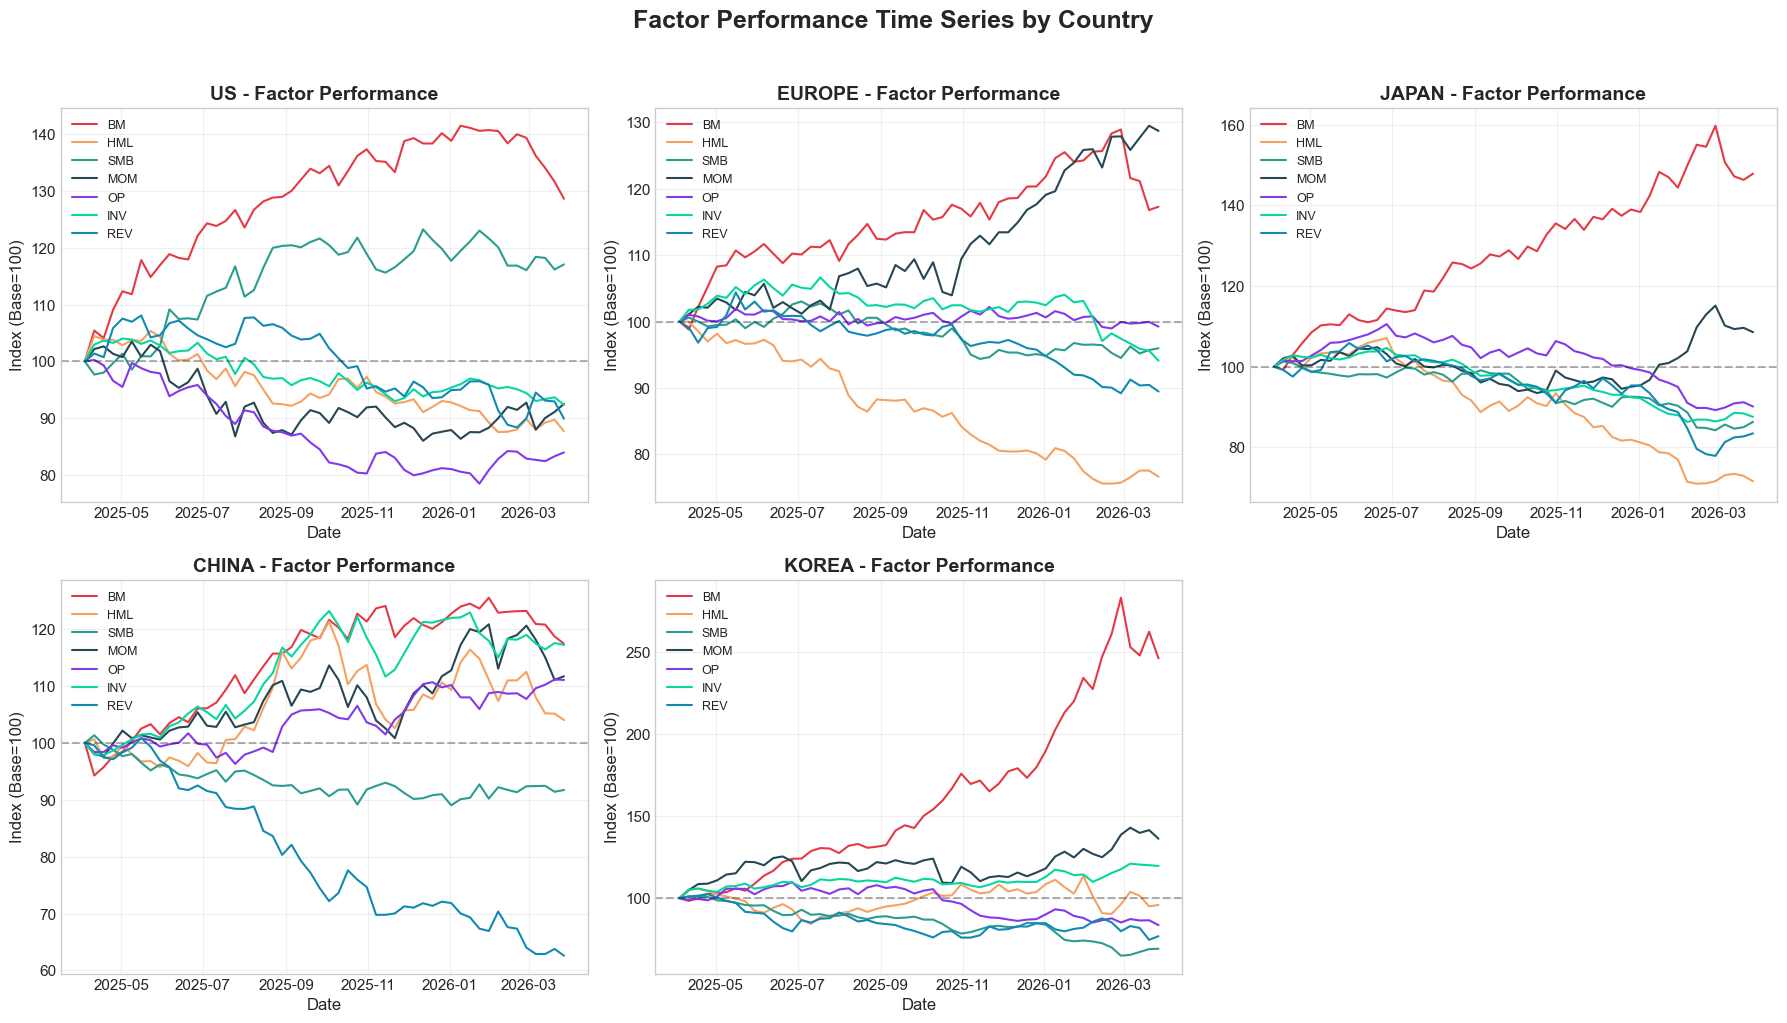

In [6]:
# Plot factor time series for each country
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_ts = data['factor_hs_clipped'][country]

    for col in factor_ts.columns:
        if col in FACTOR_COLORS:
            ax.plot(factor_ts.index, factor_ts[col], label=col,
                   color=FACTOR_COLORS.get(col, 'gray'), linewidth=1.5)

    ax.axhline(y=100, color='black', linestyle='--', alpha=0.3)
    ax.set_title(f'{country.upper()} - Factor Performance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Index (Base=100)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

plt.suptitle('Factor Performance Time Series by Country', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
# Calculate factor statistics
def calculate_factor_stats(factor_ts):
    """Calculate comprehensive factor statistics"""
    returns = factor_ts.pct_change().dropna()

    stats = pd.DataFrame({
        'Total Return (%)': ((factor_ts.iloc[-1] / factor_ts.iloc[0]) - 1) * 100,
        'Ann. Return (%)': returns.mean() * 52 * 100,
        'Ann. Vol (%)': returns.std() * np.sqrt(52) * 100,
        'Sharpe Ratio': (returns.mean() * 52) / (returns.std() * np.sqrt(52)),
        'Max Drawdown (%)': ((factor_ts / factor_ts.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    })
    return stats.round(3)

# Display factor stats for each country
for country in COUNTRIES:
    print(f"\n{'='*70}")
    print(f"{country.upper()} - FACTOR STATISTICS")
    print("="*70)
    stats = calculate_factor_stats(data['factor_hs_clipped'][country])
    display(stats.style.format('{:.3f}').background_gradient(cmap='RdYlGn', subset=['Sharpe Ratio'], axis=0))


US - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,28.616,26.695,14.177,1.883,-9.076,0.652,0.262
HML,-12.279,-12.619,12.135,-1.040,-16.895,0.321,-0.034
SMB,17.068,17.100,14.380,1.189,-5.832,0.273,0.651
MOM,-7.468,-6.356,17.709,-0.359,-16.874,-0.464,0.430
OP,-15.998,-17.007,12.295,-1.383,-21.701,0.733,1.242
INV,-7.625,-7.692,8.920,-0.862,-11.203,0.415,0.373
REV,-10.071,-9.810,14.317,-0.685,-18.227,0.496,1.265



EUROPE - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,17.294,17.058,12.472,1.368,-9.408,-0.927,1.966
HML,-23.372,-26.707,8.592,-3.109,-24.425,-0.097,0.571
SMB,-4.031,-3.983,6.539,-0.609,-8.403,-0.223,0.015
MOM,28.704,26.684,13.514,1.975,-4.971,0.034,0.693
OP,-0.777,-0.644,5.547,-0.116,-3.175,-0.246,-0.393
INV,-5.907,-5.905,7.795,-0.758,-11.769,-0.480,0.855
REV,-10.544,-11.011,8.303,-1.326,-14.567,0.738,1.310



JAPAN - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,47.863,41.096,14.748,2.787,-8.406,-0.393,0.373
HML,-28.458,-33.004,14.380,-2.295,-33.733,-0.617,1.165
SMB,-13.707,-14.596,9.157,-1.594,-16.843,-0.505,1.415
MOM,8.542,9.256,13.550,0.683,-10.867,0.700,1.539
OP,-9.903,-10.159,9.704,-1.047,-19.300,-0.229,0.865
INV,-12.469,-13.366,6.304,-2.120,-17.530,0.177,-0.367
REV,-16.548,-17.394,14.389,-1.209,-26.440,0.064,1.021



CHINA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,17.435,17.299,13.384,1.292,-6.437,-0.959,1.426
HML,4.003,5.761,18.910,0.305,-15.425,-0.199,-0.252
SMB,-8.281,-8.387,9.240,-0.908,-12.141,0.192,-0.004
MOM,11.707,12.896,18.010,0.716,-11.259,-0.340,-0.197
OP,11.066,11.249,10.495,1.072,-5.284,0.374,0.450
INV,17.221,17.076,13.173,1.296,-9.355,-0.232,-0.627
REV,-37.410,-46.165,16.795,-2.749,-37.935,0.227,0.823



KOREA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,146.355,96.388,27.227,3.540,-13.062,-0.777,1.224
HML,-4.138,0.156,30.052,0.005,-20.408,-0.204,0.767
SMB,-30.869,-36.191,16.225,-2.231,-35.745,-0.724,0.714
MOM,36.275,35.329,27.173,1.300,-13.005,-0.803,2.302
OP,-16.441,-16.784,17.429,-0.963,-23.875,-0.139,-0.219
INV,19.660,19.170,13.102,1.463,-6.336,0.167,0.113
REV,-23.224,-24.031,24.074,-0.998,-27.247,0.205,0.651


### Factor Correlation Analysis

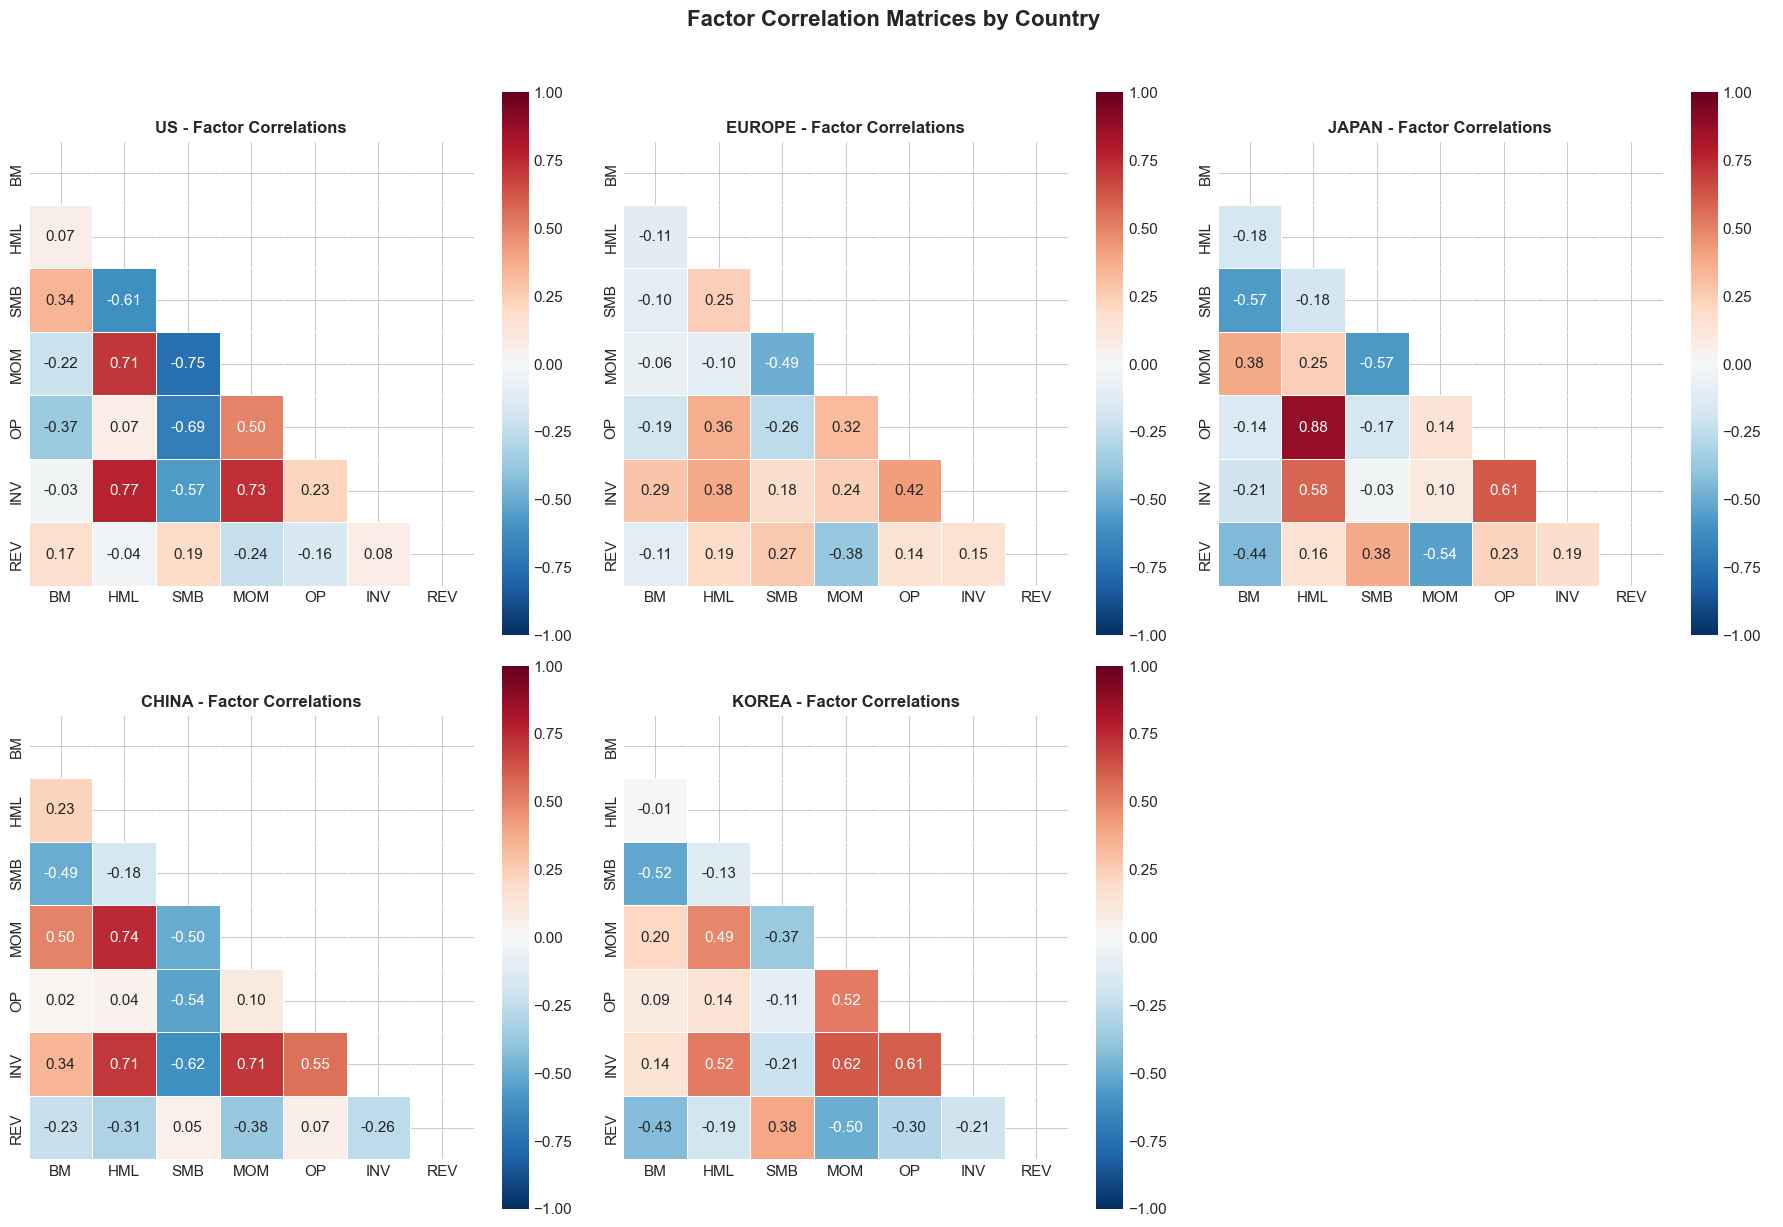

In [8]:
# Factor correlation matrices
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_returns = data['factor_hs_clipped'][country].pct_change().dropna()
    corr = factor_returns.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, ax=ax, vmin=-1, vmax=1,
                square=True, linewidths=0.5)
    ax.set_title(f'{country.upper()} - Factor Correlations', fontsize=12, fontweight='bold')

axes[5].axis('off')
plt.suptitle('Factor Correlation Matrices by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [9]:
# === LLM Commentary: Historical Analysis ===
_hist_txt = "HISTORICAL ANALYSIS - Factor Performance & Correlations\n\n"

# Part A: Factor Statistics (52w + recent 4/8w)
_hist_txt += "=== PART A: FACTOR PERFORMANCE STATISTICS ===\n\n"
for _c in COUNTRIES:
    _hs = data['factor_hs_clipped'][_c]
    _full = calculate_factor_stats(_hs)
    _ret4  = (_hs.iloc[-1] / _hs.iloc[-5]  - 1) * 100 if len(_hs) >= 5  else pd.Series(dtype=float)
    _ret8  = (_hs.iloc[-1] / _hs.iloc[-9]  - 1) * 100 if len(_hs) >= 9  else pd.Series(dtype=float)
    _prior4 = (_hs.iloc[-5] / _hs.iloc[-9] - 1) * 100 if len(_hs) >= 9  else pd.Series(dtype=float)
    _accel  = _ret4 - _prior4
    _hist_txt += f"{'='*38}\n{_c.upper()}\n{'='*38}\n"
    _hist_txt += "Factor | Sharpe | MaxDD(%) | 4w Ret(%) | 8w Ret(%) | Accel\n"
    for _f in _full.index:
        _sh  = _full.loc[_f, 'Sharpe Ratio']
        _dd  = _full.loc[_f, 'Max Drawdown (%)']
        _r4  = _ret4.get(_f,   float('nan'))
        _r8  = _ret8.get(_f,   float('nan'))
        _acc = _accel.get(_f,  float('nan'))
        _dir = "ACCEL↑" if _acc > 0 else "DECEL↓"
        _hist_txt += (
            f"  {_f:5}: Sharpe={_sh:+.2f} | MaxDD={_dd:.1f}% "
            f"| 4w={_r4:+.2f}% | 8w={_r8:+.2f}% | {_dir}({_acc:+.2f}%)\n"
        )
    _hist_txt += "\n"

# Part B: Factor Correlations (full 52w + recent 8w change)
_hist_txt += "=== PART B: FACTOR CORRELATIONS ===\n\n"
for _c in COUNTRIES:
    _ret_full   = data['factor_hs_clipped'][_c].pct_change().dropna()
    _ret_recent = data['factor_hs_clipped'][_c].iloc[-8:].pct_change().dropna()
    _corr_full   = _ret_full.corr().round(2)
    _corr_recent = _ret_recent.corr().round(2) if len(_ret_recent) >= 3 else _corr_full
    _corr_diff   = (_corr_recent - _corr_full).round(2)
    _hist_txt += f"{'='*32}\n{_c.upper()}\n{'='*32}\n"
    _hist_txt += "Full-Period Correlation:\n" + _corr_full.to_string() + "\n"
    _hist_txt += "Recent 8-Week Correlation:\n" + _corr_recent.to_string() + "\n"
    _hist_txt += "Change (Recent - Full):\n" + _corr_diff.to_string() + "\n\n"

_hist_prompt = (
"당신은 지금 1.3 Historical Analysis 섹션 종합 해설을 작성합니다.\n\n"
"제공된 데이터는 두 파트로 구성됩니다: "
"Part A — 5개 시장별 7개 팩터의 52주 통계(Sharpe, MaxDD) + 최근 4주/8주 수익률 및 변화(Change) "
"Part B — 전체 기간 vs 최근 8주 팩터 상관관계 행렬, 그리고 그 변화(Change)\n"
"다음 흐름으로 서술하십시오: "
"1.최근 4~8주 기준으로 가속 중인 팩터와 감속 중인 팩터를 구분하여 가장 중요한 변화부터 서술하십시오. "
"2.52주 Sharpe와 최근 추세가 상충하는 팩터(예: 장기 강세이나 최근 감속)를 지적하고, 이것이 의미하는 국면 전환 신호인지 논의하십시오. "
"3.**상관관계 변화 행렬(Change)**에서 가장 큰 움직임을 포착하여, 어떤 팩터가 서로 동행하는지, 혹은 반대되는지 서술하십시오. "
"4.Part A와 Part B를 통합하여 현재 팩터 환경의 구조적 특성과 투자 시사점을 도출하십시오.\n"
"최근 4~8주 변화에 서술의 무게를 두고, 52주 맥락은 배경으로만 간략히 언급하십시오. "
)

show_explanation(_hist_txt, _hist_prompt, title="1.3 Historical Analysis 종합 해설의 실무적 구성")


---
### 💬 1.3 Historical Analysis 종합 해설의 실무적 구성

1. 최근 4~8주 기준 가속·감속 팩터 식별 및 우선순위 요약  
  1.1 도입: 최근 4~8주 동향을 기준으로 팩터별 속도 변화(Accel)를 비교하면 시장 전반에서 공통적으로 드러나는 패턴과 지역별 특화된 변화가 병존함이 확인됨.  
  1.2 근거 및 해석: 가장 눈에 띄는 공통 신호는 시장 베타(BM)의 전역적 감속(미·유럽·일본·중국·한국 대부분에서 Accel 음수, 특히 한국 -33.93%, 일본 -18.07%, 유럽 -12.77%)임. 이는 4주 수익률에서 BM의 급락(예: 유럽 -9.02%, 한국 -13.06%)과 8주 대비 가속도 감소로 드러남. 반면 소형주(SMB)는 미국·유럽·일본·한국에서 가속(미 +5.47, 유럽 +3.59, 일본 +9.19, 한국 +18.98)되어 최근 소형주 상대성과가 강화되는 국면이 관찰됨. 수익성(운영성, OP)은 중국·일본·유럽에서 가속(중 +4.03, 일 +7.05, 유럽 +0.02)하여 ‘퀄리티’ 선호 신호가 일부 아시아·유럽에서 동시적으로 나타남. REV(단기반전)도 미국·일본에서 강력한 가속(미 +6.08, 일 +19.43)을 보이며 단기 평균회귀형 트레이딩 기회가 증가하고 있음.  
  1.3 투자 시사점: 단기(4–8주) 중심으로는 전통적 시장 베타 비중 축소와 함께 지역별로 소형주 및 선별적 퀄리티(특히 중국·일본)에 대한 전술적 확대를 권고함. REV 가속은 단기 반등·오버슈팅 포착 전략(숏 커버, 이벤트 기반 롱)을 더 빈번히 활용할 근거가 됨. 다만 소형주와 REV는 변동성이 크므로 포지션 사이즈·유동성 규칙을 엄격히 적용할 필요 있음.

2. 52주 Sharpe와 최근 추세가 상충하는 팩터들의 해석 — 국면 전환 신호 여부  
  2.1 도입: 52주 기간의 Sharpe(연속적 위험조정 성과)를 배경으로 최근 4–8주 추세와 충돌하는 경우, 이는 일시적 조정인지 구조적 전환인지 판단이 필요함.  
  2.2 근거 및 해석: 대표적 상충 사례는 BM임. 예컨대 한국(BM Sharpe +3.54)·일본(+2.79)·미국(+1.88)은 연간 기준으로 BM이 강력한 성과를 냈음에도 최근 4주 급락과 가속도 음수가 동시 발생함. 이는 단순한 팩터 변동성 확대보다는 광범위한 리스크 감수 기피로 해석될 위험이 큼. 반면 유럽의 MOM(Sharpe +1.98)은 장기간 강세에도 최근 약간의 감속이 있어 모멘텀 지속성 약화의 초기 신호일 가능성이 있으나 아직 완전한 역전으로 보기 어려움. 또한 HML(가치)은 유럽·일본·한국에서 4–8주 가속을 보이는데(예: 일본 HML Accel +6.92, 한국 +14.77) 장기 Sharpe가 음수인 경우(유럽 HML Sharpe -3.11) 이는 일시적 밸류 리레이팅 또는 경기성장 재평가의 신호일 수 있으므로 신중한 확인 필요.  
  2.3 투자 시사점: BM의 동시다발적 약화는 시장 전체 리스크 선호 변화의 선행 신호로 간주하고 방어적 포지셔닝(디플레·증시침체 대비 헷지, 레버리지 축소)을 고려할 것. 가치(HML)의 최근 가속은 컨트라리안(역발상) 차별화 기회이나 장기 저조한 Sharpe를 감안하여 회복 지속성(8주 이후 추적) 확인 후 리밸런싱 적용 권고.

3. 상관관계 변화 행렬(Change)에서 포착된 주요 구조적 이동 및 상호관계 해석  
  3.1 도입: 최근 8주 기준 상관관계의 변화는 팩터 간 동행·역행 구조가 재편되고 있음을 시사함.  
  3.2 근거 및 해석(주요 시장별 요점):  
    - 미국: MOM–REV 간 음의 공고화(최근상관 MOM vs REV = -0.83, 변화 -0.59)로 모멘텀과 단기반전이 강한 분리 상태에 있음. 또한 BM–HML 상관(+0.46 변화) 상승은 가치가 시장과 더 동조화됐음을 의미.  
    - 유럽: BM–SMB 간 급격한 분리(변화 -0.77, 최근 상관 -0.87) 및 BM–REV 부(-0.69) 강화는 시가총액·시장베타 간 전통적 관계 역전이나 대조적 움직임을 형성. MOM–INV 상관 증가(+0.61)은 모멘텀과 보수적 투자성향(INV)이 최근 함께 움직이는 독특한 동학을 시사.  
    - 일본: MOM과 REV의 강한 반대(최근 -0.98) 및 BM–OP 급변(-0.68)은 모멘텀이 반전과 극명히 분리되고 이익기반(OP)이 시장 방향성과 반대로 움직이는 구조적 이탈을 의미.  
    - 중국: OP가 BM/HML/MOM과 강하게 음의 재배열(예: OP–HML 변화 -0.81, OP–MOM -0.81)되었고 SMB–BM의 양(변화 +0.78)이 커지며 ‘퀄리티 대형·모멘텀’ 대비구조가 재편됨. OP와 INV 간 변화(-1.10)는 수치상 과도하지만 두 팩터 관계의 극적 재정렬을 가리킴(자료의 수치적 한계 주의).  
    - 한국: REV와 OP/INV 간 상관 증가(REV–OP +0.54, REV–INV +0.47)로 단기반전이 퀄리티·보수성 팩터와 연동되는 경향이 강화됨.  
  3.3 투자 시사점: 전역적 공통점은 ‘모멘텀 ↔ 반전’ 이분법의 심화이며, 지역별로는 BM–SMB·BM–HML 관계의 재편이 나타남. 포트폴리오 레벨에서는 팩터 간 상호작용(공동 상승/하락 리스크)을 정교하게 반영한 헤지·커버 전략(예: MOM 롱·REV 숏 vs MOM 숏·REV 롱 동적 운영)이 필요함.

4. Part A와 Part B 통합을 통한 현재 팩터 환경의 구조적 특성 및 전술적·전략적 시사점  
  4.1 도입: 성과 통계(Part A)와 상관관계 재편(Part B)을 통합하면 단기적으로는 ‘분극화·선택적 회전’이, 중기적으로는 ‘구조적 재상관(re-correlation)’ 가능성이 동시에 관찰됨.  
  4.2 구조적 특성:  
    - 베타 약화와 소형주·퀄리티 동시강화의 불균형: BM의 동시 감속과 SMB·OP의 지역별 가속은 ‘시장 전체보다 개별 펀더멘털·지수 구성요소에 따른 차별화’가 강화되는 국면을 의미함.  
    - 모멘텀과 단기반전의 명확한 분리: 여러 시장에서 MOM–REV의 음의 공고화가 나타나 트렌드 추종자와 평균회귀 트레이더 간 스타일 충돌이 심화됨.  
    - 지역별 이질성 확대: 중국·일본에서는 OP가 시장·모멘텀과 역방향으로 재편되는 반면, 미국·유럽은 HML·SMB 등 전통 팩터의 재결합·분리 양상이 달리 전개됨.  
  4.3 투자 시사점(전술적·전략적 권고):  
    - 전술적 조치: 단기적으로 BM 노출을 축소하고(특히 한국·일본·유럽에서 신속한 방어), 소형주 가속 지역에서는 선택적 롱·롱-숏 전략(유동성·밸류에이션 필터 적용)으로 알파 추구 권장. REV 가속 지역은 이벤트·퀀트 숏커버 전략으로 수익 기회 존재.  
    - 포트폴리오 구성 원칙: 팩터간 빠른 상관 재편을 반영하여 다각화가 아닌 ‘상관성 기반 헤지(예: MOM·REV 상반 포지션, BM–SMB 디레버리지)’ 적용. 퀄리티(OP) 가속 지역은 방어적 핵심으로 편입하되, 중국·일본의 OP–시장 역관계는 역동적 리밸런싱 필요.  
    - 리스크 관리: 상관성 변동성이 확대된 만큼 스트레스 시나리오(동일 방향의 팩터 손실)에 대응한 유동성·레버리지 제한, 팩터별 최대 낙폭(MaxDD) 고려한 포지션 척도 적용을 권고(예: OP·SMB의 과거 MaxDD와 최근 가속성을 병기).  
  4.4 결론적 판단: 현재 관찰되는 빠른 가속·상관성 재편성은 ‘단기간 내에 팩터 로테이션이 빈번하게 발생하는 전술적 기회’를 제공하나, 이는 동시에 장기적 추세 전환을 의미한다고 단정하기에는 이르므로(52주 Sharpe와의 불일치를 면밀히 모니터링) 단기성 신호를 우선시하되, 8주 이후 지속성 확인 시 전략적 포지셔닝 전환을 고려할 것을 권고함.

---

---
## Stock Market(Country) Analysis

### Market Expected Returns

MARKET-LEVEL ANALYSIS

⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries
    because factor models have different scales/calibrations.

[1] MARKET ER - (z-score scales)
----------------------------------------------------------------------


,Weighted Mean ER (%)
US,-0.4587
EUROPE,-0.1383
JAPAN,-0.1476
CHINA,-1.2557
KOREA,1.2823



[2] CROSS-COUNTRY COMPARABLE METRICS
----------------------------------------------------------------------


,Market ER Percentile,Market ER Z-Score,% Stocks Positive ER,ER Dispersion (Q80-Q20),ER Sharpe (mean/std)
Country,,,,,
US,26.4,-0.46,55.1%,4.2076,0.023
EUROPE,38.5,-0.14,67.1%,1.6430,0.053
JAPAN,42.2,-0.15,81.8%,0.8199,0.055
CHINA,13.3,-1.26,54.8%,1.2370,0.006
KOREA,91.2,1.28,99.0%,4.1838,0.260



Interpretation Guide:
  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods
  • % Stocks Positive ER: Higher = More bullish signal for the market
  • ER Sharpe: Higher = More consistent positive signal across stocks


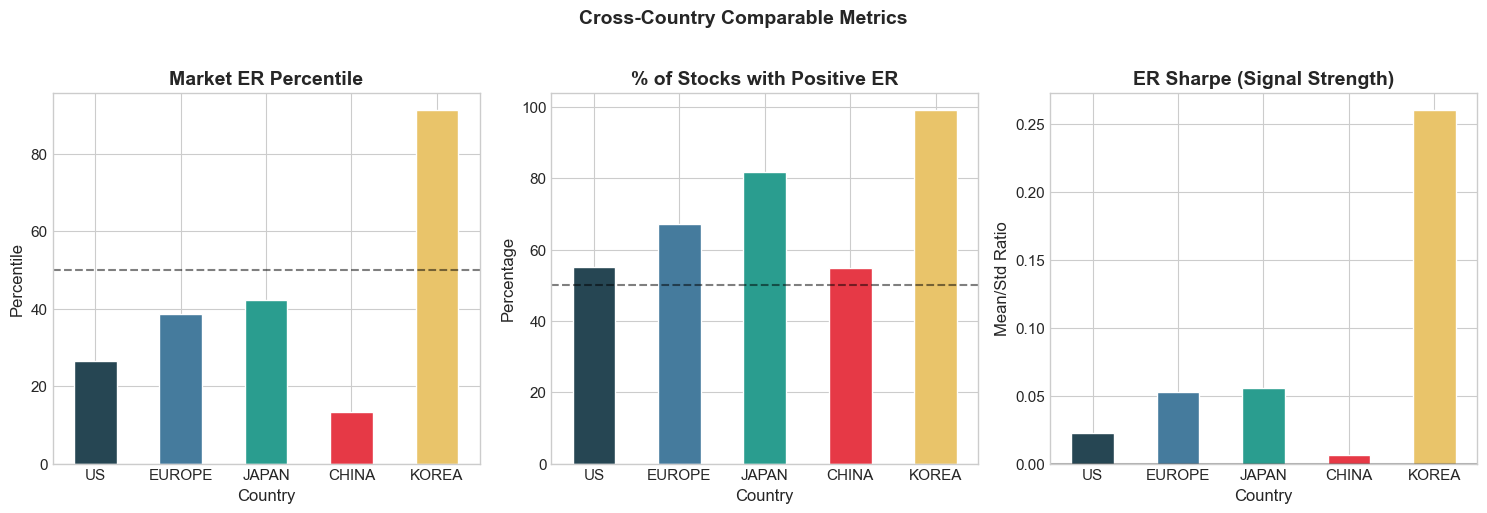

In [10]:
# Market-level expected returns comparison - WITH NORMALIZATION CONTEXT
print("="*70)
print("MARKET-LEVEL ANALYSIS")
print("="*70)
print("\n⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries")
print("    because factor models have different scales/calibrations.\n")

# Raw market ERs
market_er = {}
for country in COUNTRIES:
    wmean = data['index_ER'][country]['ER_zscore'].iloc[0]
    market_er[country.upper()] = wmean

market_er_df = pd.DataFrame([market_er], index=['Weighted Mean ER (%)']).T

print("[1] MARKET ER - (z-score scales)")
print("-"*70)
display(market_er_df.style.format('{:.4f}'))

# Calculate comparable metrics using within-country distribution
print("\n[2] CROSS-COUNTRY COMPARABLE METRICS")
print("-"*70)

comparable_metrics = []
for country in COUNTRIES:
    total_stock_er = data['total_ER'][country]
    index_total_history_er = data['index_ts'][country]['index_ER']
    index_er = data['index_ER'][country]['wER'].iloc[0]

    # What percentile is the market ER within its own distribution?
    market_percentile = (index_er/100 > index_total_history_er).mean() * 100

    # Z-score of market ER within country
    market_zscore = data['index_ER'][country]['ER_zscore'].iloc[0]

    # Stock-wise
    er_values = total_stock_er['ER'].dropna()
    sh_values = total_stock_er['Sharpe'].dropna()

    # Percentage of stocks with positive ER
    pct_positive = (er_values > 0).mean() * 100

    # Spread between top and bottom quintile
    er_spread = er_values.quantile(0.8) - er_values.quantile(0.2)

    # Sharpe-like metric: mean ER / std ER
    er_sharpe = sh_values.mean()

    comparable_metrics.append({
        'Country': country.upper(),
        'Market ER Percentile': market_percentile,
        'Market ER Z-Score': market_zscore,
        '% Stocks Positive ER': pct_positive,
        'ER Dispersion (Q80-Q20)': er_spread,
        'ER Sharpe (mean/std)': er_sharpe
    })

comparable_df = pd.DataFrame(comparable_metrics).set_index('Country')
display(comparable_df.style.format({
    'Market ER Percentile': '{:.1f}',
    'Market ER Z-Score': '{:.2f}',
    '% Stocks Positive ER': '{:.1f}%',
    'ER Dispersion (Q80-Q20)': '{:.4f}',
    'ER Sharpe (mean/std)': '{:.3f}'
}).background_gradient(cmap='RdYlGn', axis=0))

print("\nInterpretation Guide:")
print("  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods")
print("  • % Stocks Positive ER: Higher = More bullish signal for the market")
print("  • ER Sharpe: Higher = More consistent positive signal across stocks")

# Bar chart of comparable metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Market Percentile
ax = axes[0]
colors = [COUNTRY_COLORS[c.lower()] for c in comparable_df.index]
comparable_df['Market ER Percentile'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('Market ER Percentile', fontweight='bold')
ax.set_ylabel('Percentile')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 2: % Positive ER
ax = axes[1]
comparable_df['% Stocks Positive ER'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('% of Stocks with Positive ER', fontweight='bold')
ax.set_ylabel('Percentage')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 3: ER Sharpe
ax = axes[2]
comparable_df['ER Sharpe (mean/std)'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('ER Sharpe (Signal Strength)', fontweight='bold')
ax.set_ylabel('Mean/Std Ratio')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cross-Country Comparable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [11]:
# === LLM Commentary: Stock Market Analysis ===
_market_txt = "STOCK MARKET (COUNTRY-LEVEL) ANALYSIS - Current + Recent Trend\n\n"

for _c in COUNTRIES:
    _total_er  = data['total_ER'][_c]
    _idx_ts    = data['index_ts'][_c]['index_ER']
    _idx_er    = data['index_ER'][_c]['wER'].iloc[0]
    _pctile    = (_idx_er / 100 > _idx_ts).mean() * 100
    _zscore    = data['index_ER'][_c]['ER_zscore'].iloc[0]
    _pct_pos   = (_total_er['ER'].dropna() > 0).mean() * 100
    _er_sharpe = _total_er['Sharpe'].dropna().mean()
    _z4w = float(_idx_ts.iloc[-5])  if len(_idx_ts) >= 5  else float('nan')
    _z8w = float(_idx_ts.iloc[-9])  if len(_idx_ts) >= 9  else float('nan')
    _cur = float(_idx_ts.iloc[-1])
    _chg4 = _cur - _z4w
    _chg8 = _cur - _z8w
    _trend = "IMPROVING" if _chg4 > 0 else "DETERIORATING"
    _market_txt += (
        f"{_c.upper()}: Percentile={_pctile:.1f}% | Z-Score={_zscore:+.2f} | "
        f"StocksPositiveER={_pct_pos:.1f}% | AvgSharpe={_er_sharpe:.3f}\n"
        f"         ER Trend: cur={_cur:.4f} | 4w-ago={_z4w:.4f} | 8w-ago={_z8w:.4f} "
        f"| 4w-chg={_chg4:+.4f} | 8w-chg={_chg8:+.4f} ↑ {_trend}\n\n"
    )

_market_prompt = (
"당신은 지금 1.4 Stock Market Analysis 섹션 종합 해설을 작성합니다. \n"
"제공된 데이터: 5개 시장별 시장 기대수익률(ER) 현재 수준(백분위, Z-스코어) + 최근 4주/8주 변화 방향. \n\n"
"다음 흐름으로 서술하십시오: "
"최근 4~8주 기준으로 기대수익률 추세가 가장 빠르게 개선 또는 악화되고 있는 시장을 먼저 지목하십시오. "
"현재 절대 수준(백분위, Z-스코어)과 최근 추세 방향이 상충하는 시장을 경계 신호로 명시하십시오. (예: 저평가되어 있으나 추세는 계속 악화 등) "
"글로벌 동조화 여부 — 5개 시장의 ER 추세가 같은 방향으로 움직이는지, 또는 차별화되고 있는지 논의하십시오. \n"
"최근 ER 모멘텀에 근거한 지역 비중 조절 방향을 제시하십시오."
)

show_explanation(_market_txt, _market_prompt, title="1.4 Stock Market Analysis 종합 해설")


---
### 💬 1.4 Stock Market Analysis 종합 해설

1. 최근 4–8주 기준에서 ER(기대수익률) 추세의 빠른 개선·악화 시장 지목  
  1.1 도입: 최근 4주 변화폭을 우선으로 삼아 시장별 ER 모멘텀의 속도를 비교한 결과, 개선·악화의 강도가 명확하게 구분됨.  
  1.2 근거 및 해석: 가장 빠르게 개선된 시장은 한국으로 확인되며, 4주 ER 변화가 +0.0721(4주 전 0.0557 → 현재 0.1278)로 다른 시장을 크게 앞섬. 이어서 유럽(+0.0110)·중국(+0.0041)이 완만하게 개선되는 모습임. 반대로 악화가 가장 빠른 곳은 미국(4주 변화 -0.0238)이며, 일본도 -0.0179로 개선세가 둔화되고 있음.  
  1.3 투자 시사점: 단기 트레이딩 관점에서는 한국 중심으로 적극적 포지셔닝을 검토하되, 미국·일본은 방어적 비중 축소(또는 헤지) 우선 적용 권고.

2. 절대 수준(백분위·Z-스코어)과 최근 추세의 상충 여부 — 경계 신호 식별  
  2.1 도입: 절대 밸류(백분위·Z-스코어)와 단기 모멘텀의 결합은 ‘저평가·회복가능성’ 또는 ‘고평가·과열’ 여부를 판별하는 핵심임.  
  2.2 근거 및 해석: 중국은 Percentile 13.3, Z-Score -1.26로 절대적으로 매우 저평가 상태이면서 ER이 최근 꾸준히 개선(8주 +0.0111, 4주 +0.0041)되고 있어 ‘저평가 대비 회복 초기’ 신호로 해석됨 — 기회이지만 거시·정책 리스크 유의 필요. 반대편으로 한국은 Percentile 91.2·Z +1.28로 이미 높은 평가구간에 위치하면서 ER이 급속히 개선되어 과열 우려 존재 — 모멘텀은 강하지만 리스크 관리 필요. 미국은 Percentile 26.4·Z -0.46로 저평가권인데도 ER 모멘텀이 악화되고 있어 ‘저평가이나 수급·모멘텀 약화’의 경계 신호로 판단됨. 일본은 중간(Percentile 42.2·Z -0.15)이지만 최근 4주 추세 악화로 상승 지속력 불확실.  
  2.3 투자 시사점: 중국은 구조적 리스크를 감안한 점진적 비중 확대(리스크 제어용 트리거 설정) 검토, 한국은 모멘텀 추종을 하되 포지션 크기·이익 실현 규칙 엄격 적용, 미국은 저가 매수보다는 모멘텀 회복 확인 이후 재진입 권고.

3. 글로벌 동조화 여부 — ER 추세의 동향성 분석  
  3.1 도입: 5개 시장의 ER 추세가 동일 방향으로 움직이는지 여부는 글로벌 리스크온/오프 동조화의 강도를 가늠케 함.  
  3.2 근거 및 해석: 현재 관찰되는 패턴은 동조화라기보다 차별화가 우세함. 한국·유럽·중국은 개선 국면(특히 한국은 급등), 미국·일본은 동시에 약화되는 이분화된 움직임을 보임. 이는 지역별 거시·유동성·구성(예: 한국의 고베타·수익성 회복, 중국의 정책 모멘텀 기대) 요인이 상이하게 작용함을 의미함. 또한 지난 섹션에서 관찰된 팩터 재편(예: BM 약화·SMB 일부 지역 가속)과도 연계되어, 시장별 ER 변화는 팩터 구조 변화와 동행하는 경우가 많음.  
  3.3 투자 시사점: 글로벌 단일 베팅보다는 지역별 차별화 포지셔닝(모멘텀·밸류·팩터 노출을 결합한 지역 선택)이 현재로서는 더 합리적임.

4. 최근 ER 모멘텀 기반의 지역 비중 조절 권고  
  4.1 도입: 단기 ER 모멘텀과 절대 밸류를 함께 반영한 전술적 비중 지침 제공.  
  4.2 권고 사항:  
    - 한국(전술적 Overweight, 단기 적극): ER 모멘텀이 압도적으로 강하고 StocksPositiveER 99%·AvgSharpe 0.260으로 단기 수익성이 높음. 다만 높은 Percentile/Z에 따른 되돌림 위험을 감안해 진입은 분할 매수·이익 실현 규칙 적용 권고.  
    - 중국(전술적 Selective Overweight, 위험조정 진입): 절대 저평가(Percentile 13.3·Z -1.26)에도 ER 개선 신호가 확인되어 컨트랙티드한 리스크 한도 내에서 선별적(정책·수급 수혜 섹터) 비중 확대 권고.  
    - 유럽(Neutral → 소폭 Overweight): ER이 꾸준히 개선되고 StocksPositiveER 67.1으로 보조 신호가 있어 중립에서 점진적 확대 가능.  
    - 미국(Underweight/Wait): 절대 수준은 낮지만 모멘텀이 최근 악화되어 재진입 전 ER·모멘텀 반전 확인 필요. 방어적 비중 축소 권고.  
    - 일본(Underweight/Selective): StocksPositiveER 높음(81.8)에도 4주 모멘텀 악화로 상승 지속성 불확실. 섹터·밸류 기반 선별적 포지션 권고.  
  4.3 리스크 관리 및 실행 규칙: 8주(중기) 확인 신호를 추가로 사용하여 모멘텀 지속성 확인, 포지션은 분할 진입·규모 제한, 환율·정책 리스크 대비 헤지 및 Stop-loss/트리거 설정 권고. 또한 팩터 재편(예: BM 약화, SMB/OP 지역별 가속)과의 정합성을 지속 모니터링하여 지역노출과 팩터노출을 동시 조정할 것.

---

---
## Factor Analysis

### Factor Expected Returns

In [12]:
# Create factor returns comparison table - RAW and NORMALIZED
print("="*70)
print("FACTOR RETURNS BY COUNTRY")
print("="*70)
print("    Use Z-Score for valid cross-country comparisons.\n")

# Z-Score normalized (within each country)
factor_zscore_df = pd.DataFrame()
for country in COUNTRIES:
    fr = data['factor_ER'][country]['ER_zscore']
    factor_zscore_df[country.upper()] = fr
factor_zscore_df = factor_zscore_df.T

print("\n[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)")
print("-"*70)
display(factor_zscore_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country factor comparison using z-scores
print("\n[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)")
print("-"*70)
print("Which factors are consistently strong/weak across all markets:")
factor_strength = factor_zscore_df.mean().sort_values(ascending=False)
for factor, zscore in factor_strength.items():
    strength = "STRONG ↑" if zscore > 0.5 else ("WEAK ↓" if zscore < -0.5 else "NEUTRAL →")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {factor:5}: {zscore:+.2f} {strength} {bar}")

FACTOR RETURNS BY COUNTRY
    Use Z-Score for valid cross-country comparisons.


[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)
----------------------------------------------------------------------


,BM,HML,INV,MOM,OP,SMB
US,-0.42,-0.79,-0.20,-1.31,-0.03,0.76
EUROPE,-0.17,-1.01,-0.22,-2.46,-0.54,0.77
JAPAN,-0.14,-1.36,-1.51,0.05,-1.15,0.29
CHINA,-1.23,-0.09,-0.21,0.41,-2.24,1.09
KOREA,1.40,0.15,0.34,2.36,-0.51,-3.02



[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)
----------------------------------------------------------------------
Which factors are consistently strong/weak across all markets:
  SMB  : -0.02 NEUTRAL → 
  BM   : -0.11 NEUTRAL → █
  MOM  : -0.19 NEUTRAL → █
  INV  : -0.36 NEUTRAL → ███
  HML  : -0.62 WEAK ↓ ██████
  OP   : -0.89 WEAK ↓ ████████


### Factor Premium Comparison

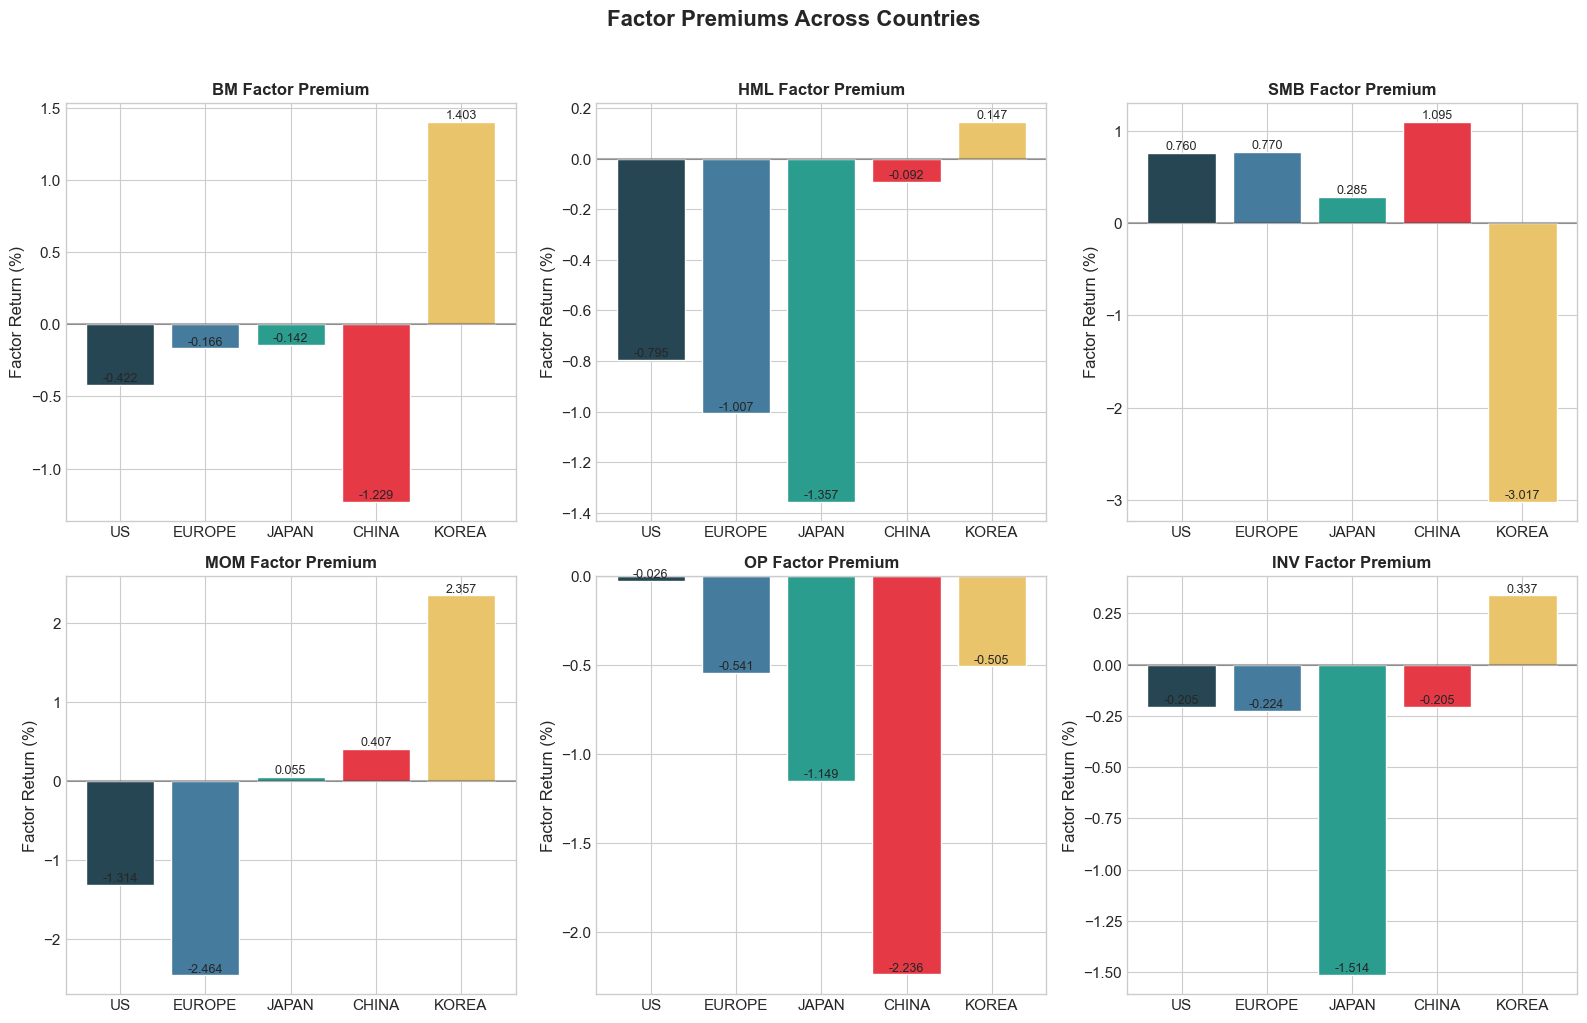

In [13]:
# Factor premium comparison across countries
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

factors = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

for idx, factor in enumerate(factors):
    ax = axes[idx]
    factor_vals = []

    for country in COUNTRIES:
        fr = data['factor_ER'][country]['ER_zscore']
        if factor in fr.index:
            factor_vals.append(fr.loc[factor])
        else:
            factor_vals.append(0)

    colors = [COUNTRY_COLORS[c] for c in COUNTRIES]
    bars = ax.bar([c.upper() for c in COUNTRIES], factor_vals, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax.set_title(f'{factor} Factor Premium', fontsize=12, fontweight='bold')
    ax.set_ylabel('Factor Return (%)')

    # Add value labels
    for bar, val in zip(bars, factor_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Factor Premiums Across Countries', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [14]:
# === LLM Commentary: Factor Analysis ===
_factor_a_txt = "FACTOR ANALYSIS \u2014 Expected Returns + Cross-Country Premiums\n\n"

# Part A: Factor ER (Z-score + 4w trend)
_factor_a_txt += "=== PART A: FACTOR EXPECTED RETURNS (Z-Score + 4-Week Trend) ===\n\n"
for _c in COUNTRIES:
    _fts   = data['factor_ts'][_c]
    _fER_z = data['factor_ER'][_c]['ER_zscore']
    _factor_a_txt += f"{'='*35}\n{_c.upper()}\n{'='*35}\n"
    _factor_a_txt += f"{'Factor':6} | Z-Score | cur ER  | 4w-ago  | 4w-chg | trend\n"
    for _f in _fER_z.index:
        _col = f"{_f}_ER"
        _z   = _fER_z.get(_f, float('nan'))
        if _col in _fts.columns and len(_fts) >= 5:
            _cur  = float(_fts[_col].iloc[-1])
            _4w   = float(_fts[_col].iloc[-5])
            _chg  = _cur - _4w
            _dir  = "↑" if _chg > 0 else "↓"
        else:
            _cur = _4w = _chg = float('nan')
            _dir = "?"
        _factor_a_txt += f"  {_f:5}: z={_z:+.2f} | {_cur:.4f} | {_4w:.4f} | {_chg:+.4f} {_dir}\n"
    _factor_a_txt += "\n"

# Global 4w average
_factor_a_txt += "GLOBAL 4-WEEK FACTOR ER CHANGE (avg across countries):\n"
_f_changes = {}
for _f in data['factor_ER'][COUNTRIES[0]]['ER_zscore'].index:
    _col = f"{_f}_ER"
    _chgs = []
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        if _col in _fts.columns and len(_fts) >= 5:
            _chgs.append(float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5]))
    if _chgs:
        _f_changes[_f] = sum(_chgs) / len(_chgs)
for _f, _chg in sorted(_f_changes.items(), key=lambda x: -x[1]):
    _dir = "↑ RISING" if _chg > 0 else "↓ FALLING"
    _factor_a_txt += f"  {_f:5}: avg 4w-chg = {_chg:+.4f}  {_dir}\n"

# Part B: Cross-country factor premiums
_factor_a_txt += "\n=== PART B: CROSS-COUNTRY FACTOR PREMIUMS (Z-Score + 4-Week Direction) ===\n\n"
_factors_list = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']
for _f in _factors_list:
    _col = f"{_f}_ER"
    _factor_a_txt += f"{_f}:\n"
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        _z   = data['factor_ER'][_c]['ER_zscore'].get(_f, float('nan'))
        if _col in _fts.columns and len(_fts) >= 5:
            _chg = float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5])
            _dir = "↑" if _chg > 0 else "↓"
        else:
            _chg, _dir = float('nan'), "?"
        _factor_a_txt += f"  {_c.upper():8}: z={_z:+.2f}  4w-chg={_chg:+.4f} {_dir}\n"
    _factor_a_txt += "\n"

_factor_prompt = (
"당신은 지금 1.5 Factor Analysis 섹션 종합 해설을 작성합니다. \n\n"
"제공된 데이터는 두 파트로 구성됩니다: "
"Part A — 5개 시장 × 7개 팩터의 현재 Z-스코어 기대수익률 + 최근 4주 변화 방향 "
"Part B — 6개 팩터별 5개 국가 Z-스코어 + 4주 변화 방향 (국가 간 비교) \n"
"다음 흐름으로 서술하십시오: "
"현재 기대수익률 모멘텀이 가장 강한 팩터(전 세계적으로 4주 연속 상승 추세)를 최우선으로 서술하십시오. "
"Z-스코어는 높으나 최근 4주 기대수익률이 하락 중인 팩터를 지적하십시오. (포지션 혼잡 또는 반전 가능성 경고) "
"국가 간 팩터 프리미엄 차별화가 가장 큰 팩터를 식별하여, 가장 매력적인 [국가-팩터] 조합을 제시하십시오. "
"Part A와 Part B를 통합하여 향후 4주간의 팩터 포지셔닝 방향을 종합 의견으로 제시하십시오. \n"
"4주 변화 방향(↑/↓)을 핵심 신호로 삼고, Z-스코어는 맥락으로만 활용하십시오. "
)

show_explanation(_factor_a_txt, _factor_prompt, title="1.5 Factor Analysis 종합 해설")


---
### 💬 1.5 Factor Analysis 종합 해설

1. 전 세계적으로 모멘텀(MOM)이 현재 가장 강한 팩터(우선 서술)  
  1.1 도입: 4주 변화(4w-chg)를 핵심 신호로 삼을 때, 글로벌 평균 관점에서 모멘텀(MOM)은 가장 큰 상승 모멘텀을 보임.  
  1.2 근거 및 해석: Part A의 국가별 값을 취합한 결과 MOM의 평균 4주 변화는 +0.0157로 모든 팩터 중 최상위에 위치하며, 유럽(+0.0122), 일본(+0.0038), 중국(+0.0044), 한국(+0.0583)에서 일관되게 상승세를 보이고 있음(미국은 거의 보합·소폭 하락 -0.0001). 이는 글로벌 트렌드 추종 심리가 최근 4주간 전반적으로 회복·강화되었음을 의미함. 모멘텀 팩터의 상승은 단기 추세자(트렌드 추종자)에게 유리한 환경을 조성하나, 모멘텀의 지역별 강약 차이가 존재하므로 단일 국가 집중보다는 지역별 선택과 리스크 관리가 요구됨.  
  1.3 투자 시사점: 향후 4주 전술적 관점에서는 MOM의 상대적 Overweight 권고(특히 한국·유럽·중국 중심). 단, 미국의 모멘텀은 보합 내지 약화 상태이므로 미국시장은 모멘텀 복원 확인 후 확대 권고.

2. Z-스코어가 높으나 최근 4주 기대수익률이 하락 중인 팩터(혼잡·반전 위험 경고)  
  2.1 도입: Z-스코어가 높다는 것은 과거 대비 팩터 프리미엄이 상대적으로 강하게 축적된 상태(포지션 몰림 가능)를 나타내며, 이와 동시에 4주 하락은 단기 반전 위험을 시사함.  
  2.2 근거 및 해석: 대표적 사례는 소형주(SMB)임. 미국(SMB z=+0.76)과 중국(SMB z=+1.09)은 Z-스코어가 높은 상태에서 최근 4주 변화가 각각 -0.0215, -0.0018로 하락 전환되었음. 글로벌 평균으로도 SMB는 4주 변화 -0.0122로 유일하게 하락하는 팩터로 집계됨. 이는 SMB에 쏠린 수요나 포지셔닝(특히 미국·중국에서의 상대적 프리미엄 누적)이 단기적으로 익스큐션 리스크와 반전 위험을 키우고 있음을 의미함.  
  2.3 투자 시사점: SMB 노출은 현재 포지션 축소·리스크 축소 권고. 이미 높은 Z-스코어 구간에서의 신규 레버리지 확대는 회피하고, 보유분은 부분 청산·헤지(인덱스 숏·베타 헷지) 또는 밸류에이션·유동성 기준으로 선별 보유할 것.

3. 국가 간 팩터 프리미엄 차별화가 가장 큰 팩터 및 최우수 [국가-팩터] 조합 제시  
  3.1 도입: 국가 간 Z-스코어 편차가 큰 팩터는 지역별 알파 기회가 높음.  
  3.2 근거 및 해석: MOM의 국가별 Z-스코어 범위가 -2.46(유럽)에서 +2.36(한국)으로 가장 넓어(대략 4.8포인트 범위) 국가 간 차별화가 가장 큼. 이는 모멘텀의 국가별 성숙도·구성(섹터·정책·수급) 차이가 크다는 뜻임. 이 가운데 한국의 MOM(z=+2.36, 4w-chg=+0.0583)은 Z-스코어가 매우 높고 4주 상승도 강해 ‘단기적으로 매력적인 [국가-팩터]’로 판단됨.  
  3.3 투자 시사점: 최우수 조합으로 한국-모멘텀을 지목하되, Z가 이미 높으므로 포지션은 분할 진입·이익 실현 규칙을 엄격히 적용. 유럽의 MOM(z=-2.46)은 상대적 저가·재진입 기회로 관찰하되, 반전 신호 여부를 확인 후 전략적 진입 권장.

4. Part A·B 통합 — 향후 4주간 팩터 포지셔닝 종합 방향  
  4.1 도입: 4주 변화(↑/↓)를 핵심으로 하되 Z-스코어로 맥락을 보완하는 방식으로 전술적 방향 제시.  
  4.2 종합 판단: 글로벌 평균으로 MOM·BM·HML·INV·OP는 4주 상승, SMB는 4주 하락. 다만 국가별 이질성이 큼(예: SMB는 유럽·일본에서 소폭 상승하는 반면 미국·중국·한국에서는 하락). 또한 SMB의 높은 Z-스코어(미·중)는 과열·혼잡 위험을 내포하며, MOM의 국가별 편차는 한국·유럽·중국에서 각각 다른 포지셔닝 기회를 제공함.  
  4.3 전술적 권고(향후 4주):  
    - Overweight: MOM (국가별 우선순위 — 한국 우선, 다음 유럽·중국·일본). 분할 진입·엄격한 트레일링 이익실현 권장.  
    - Selective Overweight: BM(시장베타) — 한국·중국·유럽에서는 BM 4주 상승 신호를 활용하되, 미국·일본에서는 BM이 하락 중이므로 중립 유지.  
    - Underweight / Trim: SMB 전반(특히 미국·중국의 SMB 포지션 축소), 고Z 포지션의 차익실현 권고.  
    - Neutral / Selective: OP·INV·HML은 평균적으로 상승 신호이나 Z-스코어가 낮거나 국가별 엇갈림 존재. 섹터·밸류 필터를 적용한 선별적 접근 권장.  
  4.4 리스크 규율: 팩터별 Z-스코어(포지셔닝 혼잡도)와 MaxDD 등 리스크 지표를 병행 검토하여 포지션 사이즈 제한, 분할 진입·청산, 상관성(특히 MOM–REV 분리) 변화 모니터링을 엄격 적용할 것.

5. 결론(단기적 요약)  
  5.1 요지: 향후 4주는 모멘텀 중심의 전술적 접근이 유효하며, SMB의 단기 약화와 높은 Z-스코어에 따른 혼잡 리스크를 우선 경계할 것. 국가별로는 한국 모멘텀이 가장 돋보이는 기회이나 과열 신호 대비 필요.  
  5.2 행동지침: MOM 주도 포지션을 지역 선택적으로 확대하되, SMB는 축소·재평가, BM은 지역별로 차별적 운용을 권고함.

---

---
## Sector Analysis

### Sector Factor Exposures

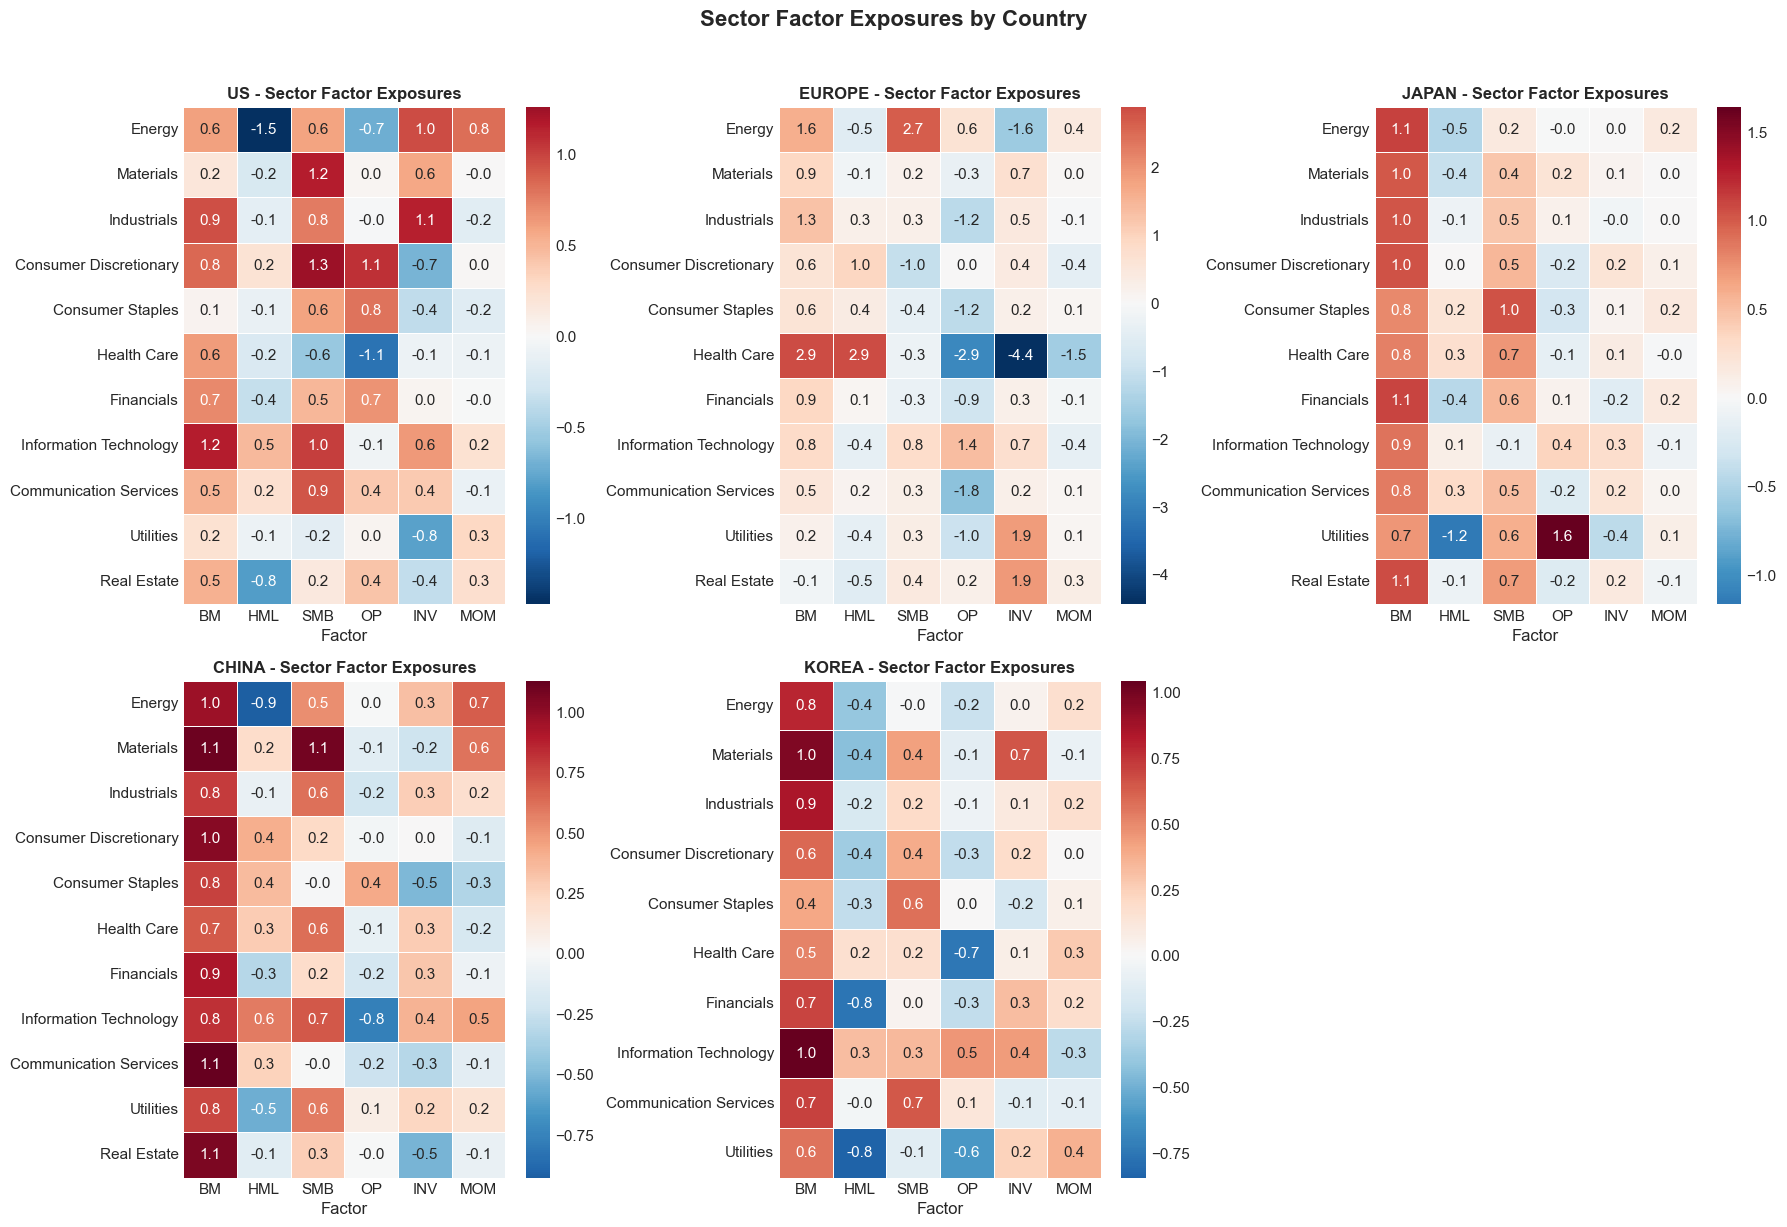

In [15]:
# Sector factor exposure heatmaps
factor_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    ind_er = data['sector_ER'][country].copy()

    # Get sector names as index
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er['Sector'] = ind_er['industry'].astype(str).map(SECTOR_NAMES)
        ind_er = ind_er.set_index('Sector')

    # Get available factor columns
    available_factors = [col for col in factor_cols if col in ind_er.columns]

    if available_factors:
        plot_data = ind_er[available_factors].dropna(how='all')
        plot_data.columns = [c.replace('beta_', '').upper() for c in plot_data.columns]

        sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='RdBu_r',
                    center=0, ax=ax, linewidths=0.5)
        ax.set_title(f'{country.upper()} - Sector Factor Exposures', fontsize=12, fontweight='bold')
        ax.set_xlabel('Factor')
        ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'No factor data available', ha='center', va='center')
        ax.set_title(f'{country.upper()}')

axes[5].axis('off')
plt.suptitle('Sector Factor Exposures by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Sector Expected Returns

In [16]:
# Sector Expected Returns comparison - RAW and NORMALIZED
print("="*90)
print("SECTOR EXPECTED RETURNS BY COUNTRY")
print("="*90)
print("\n⚠️  NOTE: Raw ER values have different scales across countries.")
print("    Use Z-Score for valid cross-country sector comparisons.\n")

# Z-Score normalized sector ERs
sector_zscore_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = data['sector_ER'][country].copy()
    ind_er = ind_er.set_index('Sector')
    sector_zscore_comparison[country.upper()] = ind_er['ER_zscore']

print("\n[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)")
print("-"*70)
display(sector_zscore_comparison.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country sector analysis
print("\n[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)")
print("-"*70)
sector_global_strength = sector_zscore_comparison.mean(axis=1).sort_values(ascending=False)
for sector, zscore in sector_global_strength.items():
    strength = "OVERWEIGHT" if zscore > 0.3 else ("UNDERWEIGHT" if zscore < -0.3 else "NEUTRAL")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {str(sector):25}: {zscore:+.2f} {strength} {bar}")

SECTOR EXPECTED RETURNS BY COUNTRY

⚠️  NOTE: Raw ER values have different scales across countries.
    Use Z-Score for valid cross-country sector comparisons.


[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)
----------------------------------------------------------------------


,US,EUROPE,JAPAN,CHINA,KOREA
Sector,,,,,
Energy,0.31,-0.03,0.02,-3.67,0.90
Materials,-0.20,0.01,-0.15,-1.11,0.82
Industrials,-0.01,-0.25,-0.14,-1.33,1.08
Consumer Discretionary,-0.76,-0.72,-0.19,-1.84,1.00
Consumer Staples,0.53,-0.54,-0.35,-1.48,0.32
Health Care,-0.78,0.15,-0.36,-0.29,-0.20
Financials,-0.48,0.03,0.00,-1.14,0.72
Information Technology,-0.58,-0.09,-0.11,-0.41,1.53
Communication Services,-0.12,-0.18,-0.29,-0.89,0.67



[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)
----------------------------------------------------------------------
  Information Technology   : +0.07 NEUTRAL 
  Materials                : -0.13 NEUTRAL █
  Industrials              : -0.13 NEUTRAL █
  Communication Services   : -0.16 NEUTRAL █
  Financials               : -0.17 NEUTRAL █
  Real Estate              : -0.25 NEUTRAL ██
  Health Care              : -0.29 NEUTRAL ██
  Utilities                : -0.30 NEUTRAL ██
  Consumer Staples         : -0.30 UNDERWEIGHT ███
  Energy                   : -0.49 UNDERWEIGHT ████
  Consumer Discretionary   : -0.50 UNDERWEIGHT █████


### Top Equities by country

In [17]:
# Top 10 stocks by Expected Return for each country
print("="*90)
print("TOP 10 STOCKS BY EXPECTED RETURN (Each Country)")
print("="*90)

for country in COUNTRIES:
    print(f"\n{'-'*70}")
    print(f"{country.upper()}")
    print("-"*70)

    top_bot = data['top_bot'][country]
    top_bot['Sector'] = top_bot['sector'].map(lambda x: SECTOR_NAMES[x], na_action='ignore')
    # Get top 10 (highest ER)
    if 'ER' in top_bot.columns:
        top10 = top_bot.nlargest(10, 'ER')[['instrument', 'Name', 'Sector', 'ER', 'Vol', 'Sharpe', 'mktval']]
        top10.columns = ['ISIN', 'Name', 'Sector', 'Expected Return(%)', 'Vol(%)', 'Sharpe(X)', 'Market Cap(Local mn)']
        top10 = top10.style.format({
            'Expected Return(%)': '{:.2f}',
            'Vol(%)': '{:.2f}',
            'Sharpe(X)': '{:.2f}',
            'Market Cap(Local mn)': '{:,.0f}',
        })
        display(top10)

TOP 10 STOCKS BY EXPECTED RETURN (Each Country)

----------------------------------------------------------------------
US
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
3,US6078281002,Modine Manufacturing Co,Industrials,11.94,17.80,0.67,"9,574"
5,US87305R1095,TTM Technologies Inc,Info Tech,11.21,17.46,0.64,"9,921"
17,US60770K1079,Moderna Inc,Health Care,9.40,18.81,0.50,"15,966"
4,US55405Y1001,MACOM Technology Solutions Holdings Inc,Info Tech,8.44,12.80,0.66,"13,949"
1,US2193501051,Corning Inc,Info Tech,7.03,9.52,0.74,"75,828"
14,US36828A1016,GE Vernova Inc,Industrials,6.49,12.79,0.51,"195,658"
8,US83443Q1031,Solstice Advanced Materials Inc,nan,6.49,11.28,0.58,"9,803"
6,US5398301094,Lockheed Martin Corp,Industrials,4.59,7.32,0.63,"145,807"
10,US6153942023,Moog Inc,Industrials,4.09,7.34,0.56,"9,468"
0,US8718291078,Sysco Corp,Consumer Staples,4.07,5.41,0.75,"40,069"



----------------------------------------------------------------------
EUROPE
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
1,PLKGHM000017,KGHM Polska Miedz SA,Materials,4.73,10.35,0.46,"10,768"
0,DE000BAY0017,Bayer AG,Health Care,4.56,9.70,0.47,"43,693"
10,GB00B2QPKJ12,Fresnillo PLC,Materials,4.53,14.33,0.32,"7,868"
18,CH0311864901,VAT Group AG,Industrials,3.62,12.64,0.29,"14,736"
4,SE0020050417,Boliden AB,Materials,3.36,9.55,0.35,"16,606"
14,DE0006766504,Aurubis AG,Materials,3.00,10.03,0.30,"4,925"
15,IT0005495657,Saipem SpA,Energy,2.91,9.90,0.29,"4,053"
2,IL0011284465,Plus500 Ltd,Financials,2.82,7.13,0.40,"3,292"
6,FR0000131104,BNP Paribas SA,Financials,2.73,7.89,0.35,"89,164"
11,LU0075646355,Subsea 7 SA,Energy,2.52,8.17,0.31,"4,896"



----------------------------------------------------------------------
JAPAN
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
15,JP3891600003,Mitsui E&S Co Ltd,Industrials,2.85,16.66,0.17,"663,299"
12,JP3888400003,Mitsui Kinzoku Co Ltd,Materials,2.71,15.32,0.18,"1,092,420"
4,JP3842400008,Hokuhoku Financial Group Inc,Financials,1.78,9.11,0.20,"577,781"
3,JP3309000002,Penta-Ocean Construction Co Ltd,Industrials,1.69,8.51,0.20,"445,998"
0,JP3230600003,Kandenko Co Ltd,Industrials,1.57,6.21,0.25,"566,474"
1,JP3443600006,Taisei Corp,Industrials,1.48,6.80,0.22,"2,514,762"
2,JP3210200006,Kajima Corp,Industrials,1.48,7.30,0.20,"2,965,599"
13,JP3877600001,Marubeni Corp,Industrials,1.46,8.31,0.18,"7,529,635"
7,JP3358800005,Shimizu Corp,Industrials,1.46,7.91,0.18,"1,431,958"
14,JP3263000006,Kinden Corp,Industrials,1.39,7.96,0.18,"763,073"



----------------------------------------------------------------------
CHINA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
3,CNE1000020V4,Victory Giant Technology HuiZhou Co Ltd,Info Tech,3.46,20.65,0.17,"142,222"
13,HK0000218211,Hua Hong Semiconductor Ltd,Info Tech,3.42,23.88,0.14,"119,215"
9,CNE100002CC3,Shenzhen Envicool Technology Co Ltd,nan,3.10,20.33,0.15,"54,931"
15,CNE100004413,VeriSilicon Microelectronics Shanghai Co Ltd,Info Tech,3.06,21.58,0.14,"66,829"
0,CA16890P1036,China Gold International Resources Corp Ltd,nan,3.01,15.89,0.19,"43,402"
10,CNE100001CY9,Zhongji Innolight Co Ltd,Info Tech,2.85,18.98,0.15,"516,667"
16,CNE100006JG0,Laopu Gold Co Ltd,Consumer Disc.,2.59,18.75,0.14,"34,397"
2,CNE1000030S9,GigaDevice Semiconductor Inc,Info Tech,2.47,14.70,0.17,"188,898"
7,CNE000000D24,Inner Mongolia Xingye Silver&Tin Mining Co Ltd,nan,2.35,15.01,0.16,"67,690"
5,CNE000000BL1,Guangdong Hec Technology Holding Co Ltd,Materials,2.33,14.46,0.16,"36,827"



----------------------------------------------------------------------
KOREA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
2,KR7402340004,SK Square Co Ltd,Industrials,11.25,18.30,0.61,"51,049,244"
17,KR7240810002,Wonik IPS Co Ltd,Info Tech,9.72,21.20,0.46,"3,314,522"
0,KR7000660001,SK Hynix Inc,Info Tech,9.40,14.09,0.67,"519,004,319"
9,KR7042700005,Hanmi Semiconductor Co Ltd,Info Tech,9.33,18.57,0.50,"8,880,956"
3,KR7006800007,Mirae Asset Securities Co Ltd,Financials,8.82,15.09,0.58,"12,215,835"
5,KR7039490008,Kiwoom Securities Co Ltd,Financials,8.19,14.90,0.55,"6,631,681"
4,KR7298040007,Hyosung Heavy Industries Corp,Industrials,8.17,14.75,0.55,"12,398,516"
15,KR7039030002,EO Technics Co Ltd,Info Tech,7.81,16.96,0.46,"3,162,179"
13,KR7000990002,DB HiTek Co Ltd,Info Tech,7.41,15.84,0.47,"3,515,436"
12,KR7010120004,LS Electric Co Ltd,Industrials,7.10,15.08,0.47,"8,668,144"


In [18]:
# === LLM Commentary: Sector Analysis ===
_sector_full_txt = "SECTOR ANALYSIS \u2014 Factor Exposures + Expected Returns + Top Equities\n\n"

# Part A: Sector factor betas
_sector_full_txt += "=== PART A: SECTOR FACTOR EXPOSURES (structural betas) ===\n\n"
_beta_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']
for _c in COUNTRIES:
    _ie = data['sector_ER'][_c].copy()
    if 'Sector' in _ie.columns:
        _ie = _ie.set_index('Sector')
    _avail = [col for col in _beta_cols if col in _ie.columns]
    if _avail:
        _exp = _ie[_avail].dropna(how='all').copy()
        _exp.columns = [col.replace('beta_', '').upper() for col in _exp.columns]
        _sector_full_txt += f"{'='*30}\n{_c.upper()}\n{'='*30}\n"
        _sector_full_txt += _exp.round(2).to_string() + "\n\n"

# Part B: Sector expected return Z-scores + 4-week trend
_sector_full_txt += "=== PART B: SECTOR EXPECTED RETURNS (Z-Score + 4-Week Trend) ===\n\n"
_sec_zscore = pd.DataFrame()
for _c in COUNTRIES:
    _ie = data['sector_ER'][_c].copy().set_index('Sector')
    _sec_zscore[_c.upper()] = _ie['ER_zscore']
_sector_full_txt += "Current Z-Score by Country:\n" + _sec_zscore.round(2).to_string() + "\n\n"

_sec_trend = pd.DataFrame()
for _c in COUNTRIES:
    _sts = data['sector_ts'][_c]
    _trends = {}
    for _col in _sts.columns:
        if _col.endswith('_ER') and len(_sts) >= 5:
            _sec_code = _col.replace('_ER', '')
            _sec_name = SECTOR_NAMES.get(_sec_code, _sec_code)
            _chg = float(_sts[_col].iloc[-1]) - float(_sts[_col].iloc[-5])
            _trends[_sec_name] = _chg
    if _trends:
        _sec_trend[_c.upper()] = pd.Series(_trends)
if not _sec_trend.empty:
    _sector_full_txt += "4-Week Sector ER Change by Country:\n"
    _sector_full_txt += _sec_trend.round(4).to_string()
    _sector_full_txt += "\n\nGlobal Average 4-Week Sector ER Change (ranked):\n"
    _global_chg = _sec_trend.mean(axis=1).sort_values(ascending=False)
    for _sec, _v in _global_chg.items():
        _arrow = "↑" if _v > 0 else "↓"
        _sector_full_txt += f"  {str(_sec):28}: {_v:+.4f} {_arrow}\n"

# Part C: Top 20 equities per country
_sector_full_txt += "\n=== PART C: TOP 20 EQUITIES BY EXPECTED RETURN ===\n\n"
for _c in COUNTRIES:
    _tb = data['top_bot'][_c].copy()
    _tb['SectorName'] = _tb['sector'].map(lambda x: SECTOR_NAMES.get(str(x), str(x)))
    if 'ER' in _tb.columns:
        _top20 = _tb.nlargest(20, 'ER')
        _sector_full_txt += f"{'='*40}\n{_c.upper()}\n{'='*40}\n"
        for _, _row in _top20.iterrows():
            _name = str(_row.get('Name', _row.get('instrument', '')))[:30]
            _sec  = str(_row.get('SectorName', ''))[:20]
            _er   = _row.get('ER', 0)
            _sh   = _row.get('Sharpe', 0)
            _sector_full_txt += f"  {_name:30} | {_sec:20} | ER={_er:.2f}% | Sharpe={_sh:.2f}\n"
        _sector_full_txt += "\n"

_sector_prompt = (
"당신은 지금 1.6 Sector Analysis 섹션 종합 해설을 작성합니다. 이것은 보고서의 마지막 섹션입니다. 제공된 데이터는 세 파트로 구성됩니다: "
"Part A — 5개 시장별 섹터의 팩터 베타(구조적 노출도) "
"Part B — 현재 섹터 기대수익률(ER) Z-스코어 + 최근 4주 변화 방향 "
"Part C — 시장별 기대수익률 상위 20개 종목(섹터, ER, Sharpe 포함)\n"
"다음 흐름으로 서술하십시오: "
"이전 섹션(1.5 Factor Analysis)에서 식별된 상승 팩터들을 연계하여, 현재 가장 수혜 가능한 섹터를 선별하십시오. (예: 팩터 베타 × 팩터 모멘텀의 교차점에서 투자 기회 발굴) "
"섹터 기대수익률 4주 변화 기준으로 가장 빠르게 개선/악화되는 섹터를 지목하고, 이것이 글로벌 공통 현상인지 특정 국가의 현상인지 구분하십시오. "
"상위 20개 종목 구성이 섹터 로테이션 분석과 일치하는지 점검하고, 불일치가 있다면 그 시사점을 논의하십시오.\n"
"보고서 전체를 통합하는 결론 단락을 작성하십시오: "
"가장 명확한 근거가 있는 단기 투자 기회 1가지 "
"가장 주의해야 할 리스크 요인 1가지\n"
"이 섹션은 보고서의 결론부이므로, 앞선 모든 섹션의 분석을 자연스럽게 수렴시키는 서술로 마무리하십시오. "
)

show_explanation(_sector_full_txt, _sector_prompt, title="1.6 Sector Analysis 종합 해설")


---
### 💬 1.6 Sector Analysis 종합 해설

1. 상승 팩터(1.5 결과)와 섹터 수혜성 교차 분석 — 유효 기회 선별  
  1.1 도입: 1.5에서 확인된 핵심 신호는 ‘모멘텀(MOM)의 글로벌 상승’과 ‘BM(시장베타)의 지역적 강화’, 그리고 ‘SMB의 전반적 약화(혼잡·반전 리스크)’임. 섹터 레벨에서는 이들 팩터에 대한 구조적 베타(Part A)를 교차해 수혜 가능 섹터를 도출함.  
  1.2 근거 및 해석: MOM 상승에 민감한 섹터(높은 MOM 베타)는 한국의 Information Technology(베타 MOM 약 -0.27으로 예외적이지만, 섹터 ER 상승 폭이 큼), 미국의 Energy( MOM 0.82), 중국의 Information Technology( MOM 0.45) 등이 있음. BM 상승(시장퀀텀 회복)에 노출된 섹터는 IT·Industrials·Energy 등으로, 특히 한국·미국에서 BM 베타가 높음. 반면 SMB가 약화되는 상황에서는 SMB 베타가 높은 Consumer Discretionary, Materials, 일부 Info Tech(미국·중국의 SMB 베타가 높은 경우)를 경계해야 함.  
  1.3 투자 시사점: 단기적으로는 MOM·BM 노출이 동시에 높은 섹터에 전술적 비중을 두되(예: 에너지·소재·정보기술 — 지역별 세분화 필요), SMB 노출이 높은 섹터는 포지션 축소 또는 헤지 적용 권고.

2. 섹터 기대수익률(4주 변화)로 본 가장 빠른 개선·악화 섹터와 지역성  
  2.1 도입: Part B의 4주 섹터 ER 변화를 근거로 글로벌·지역별 개선·악화를 구분함.  
  2.2 근거 및 해석: 글로벌 평균으로는 Energy(+0.0135), Materials(+0.0132), Health Care(+0.0119), Information Technology(+0.0113) 순으로 빠르게 개선되고 있음. 그러나 지역별로는 차별화가 뚜렷함:  
    - 한국은 Info Tech(+0.0947), Consumer Discretionary(+0.0666), Industrials(+0.0578) 등 거의 전(全)섹터에서 강한 개선을 보이며 지역적 모멘텀이 극도로 강함.  
    - 미국에서는 Energy(+0.0288), Health Care(+0.0294) 등 일부 섹터가 개선이나 Info Tech는 오히려 약화(-0.0476)로 지역별 괴리가 존재.  
    - 일본은 대체로 섹터 ER이 악화(대부분 음수)하여 개선 국면이 부재함.  
  2.3 투자 시사점: Energy·Materials·Health Care·Info Tech은 글로벌 평균 관점의 전술적 후보이나, 실행은 지역별 분해(예: 한국의 IT 및 산업 섹터 적극, 일본은 선별적 방어)로 접근할 것.

3. 상위 20개 종목 구성의 일치성 점검 및 시사점  
  3.1 도입: Part C의 상위 종목 구성이 섹터 로테이션 신호와 정합하는지 확인함.  
  3.2 근거 및 해석:  
    - 한국: 상위 20개에 정보기술(SK하이닉스 등)·산업(LS Electric 등)·금융(증권사) 비중이 높아 Sector ER 및 팩터 모멘텀(강한 MOM·BM)과 일치함. 이는 현지 모멘텀·베타 강세의 신뢰도를 높임.  
    - 중국: 상위 20개는 Info Tech·Materials 편중으로, Part B의 섹터 개선(IT·Materials)과 정합적임.  
    - 유럽: 상위 20개는 Materials·Utilities·Financials가 다수이며, 유럽의 Materials·Health Care 개선 신호와 부분적 일치.  
    - 미국: 흥미로운 불일치가 존재함. 상위 20개는 Industrials·Info Tech·Utilities·Consumer Staples 등 개별 종목 ER이 높으나, 섹터 평균 4주 변화는 Industrials·Info Tech가 약화(특히 US Info Tech -0.0476, Industrials -0.0189)로 나타남. 이는 ‘섹터 평균은 약화 중이나 개별 우량(또는 이벤트·구조적 재평가 대상) 종목들이 높은 ER을 제시’하는 현상으로 해석됨. 즉 미국은 섹터 레벨보다는 종목선별(alpha) 기회가 더 유효하다는 신호임.  
  3.3 투자 시사점: 한국·중국은 섹터·팩터 전략(지역-섹터 동시 베팅)으로 접근 가능, 미국은 섹터 대신 상위 개별 종목(아이디어·이벤트 기반) 중심으로 포지셔닝 권고.

4. 보고서 통합 결론 — 단기(다음 4주) 권고 및 리스크 강조  
  4.1 도입: 앞선 섹터·팩터·시장 분석을 종합하여 가장 명확한 단기 기회와 주의 리스크를 제시함.  
  4.2 가장 명확한 단기 투자 기회(1가지): 한국 정보기술·산업 섹터의 모멘텀 기반 전술적 Overweight. 근거는 1) 한국 시장 ER·팩터(특히 MOM·BM)의 강력한 4주 상승 신호(Part A·B·C 일관성), 2) 상위 20개 종목에 IT·Industrial 우량 종목 다수 상위 랭크로 섹터-종목 정합성 확인. 실행은 분할 진입과 엄격한 이익실현(트레일링) 규칙 적용 권고.  
  4.3 가장 주의해야 할 리스크 요인(1가지): 팩터·상관성의 급변(모멘텀 과열·포지션 혼잡에 따른 급격한 반전). 근거는 1) SMB의 전역적 약화·혼잡 신호와 2) Part B에서 관찰된 팩터 상관성 재편(예: MOM–REV 분리, BM 약화 징후)이 동시 존재함. 이는 모멘텀 기반 포지션이 급격한 리스크 오프 상황에서 동시 타격을 받을 가능성을 높임. 따라서 레버리지·포지션 사이즈 제한, 손절/헤지 규칙 필수 적용 권고.  
  4.4 최종 권고 요약: 단기적으로는 1.5에서 식별한 MOM·BM의 상승을 중심으로 섹터 선별(한국 IT·산업, 글로벌 Energy·Materials·Health Care 선별 투자)을 추진하되, Part A·B의 상관성 재편·SMB 혼잡 신호를 반영하여 포지션을 분할·헤지·엄격한 리스크 매니지먼트와 병행할 것. 보고서 전반의 결론은 ‘기회는 지역·섹터별로 분화되어 존재하나, 상관성 변동성 확대에 따른 급격한 리버설 가능성으로 보수적 실행 규율이 필수’임.

---